# **VAE Complex 2: barrido de `β` y de la dimensión latente, con un conjunto de pares de evaluación**

## **0. Introducción y objetivo**

Este notebook **parte de `VAE_complex1`**, que a su vez derivaba del último autoencoder determinista, `AE_complex2_VGG`. En `VAE_complex1` entrenamos **un único VAE** (latente de `256`, `β = 1`) y obtuvimos un FID de reconstrucción de `61.57` (igual que el de `AE_complex2_VGG`, `61.17`), un FID de generación desde el prior de `87.43`, las `256` dimensiones del latente activas y un morphing que **no mejoraba de forma visible** el de los autoencoders, medido en **un solo par de caras**. Dejamos explícitamente sin hacer lo que el README del proyecto marca como imprescindible o recomendable: variar `β`, variar la dimensión latente y evaluar el morphing con un conjunto de pares y no con uno.

Este notebook hace justo eso, con la misma arquitectura, la misma pérdida de reconstrucción (`L1 + (1 - SSIM)` más VGG con `λ = 1e-4`), el mismo optimizador (`Cosine Decay` de `1e-3` a `1e-5`), las mismas `30` épocas y el mismo lote de `128`. Lo único que cambia entre experimentos es **un factor cada vez**, como pide el README:

| Experimento del README | Qué variamos | Valores | Se mantiene fijo |
| --- | --- | --- | --- |
| **B.** Dimensión latente | `z` | `16`, `32`, `64` (y `256`, el modelo de `VAE_complex1`) | `β = 1` |
| **C.** Regularización | `β` | `0.5`, `1`, `2` | `z = 32` |
| **A.** Interpolación | lineal frente a esférica (SLERP) | los dos métodos | en todos los modelos |

El modelo base es `z = 32`, `β = 1`, que es la configuración que propone el README. El modelo `z = 256`, `β = 1` **no se vuelve a entrenar**: se carga el de `VAE_complex1` como punto de referencia. En total hay `5` entrenamientos nuevos.

**Qué aporta de nuevo respecto a `VAE_complex1`:**

- **Un conjunto fijo de `24` pares de caras** (`12` fáciles y `12` difíciles), definido a partir de los atributos y los *landmarks* de CelebA y guardado en un fichero, de modo que **el mismo conjunto pueda usarse con el morphing clásico y con la DCGAN**. Así dejamos de evaluar el morphing con un par elegido a mano.
- **Métricas de morphing por par** (uniformidad de los pasos, nitidez del punto medio, norma del latente, error en los extremos, FID de los fotogramas intermedios), con media por tipo de par y no una valoración visual de una sola secuencia.
- **Un único código de evaluación** que se aplica igual a todos los modelos.

**Limitaciones que conviene tener presentes desde el principio.**

- **Una sola semilla por configuración.** No repetimos cada entrenamiento con semillas distintas, así que no conocemos la variabilidad entre entrenamientos. Con `1000` imágenes, diferencias de FID de uno o dos puntos están en el orden del ruido de la métrica, y las conclusiones se redactarán con esa cautela.
- **El procedimiento de entrenamiento no es bit a bit el de `VAE_complex1`.** Aquí el lote de `128` se procesa en `2` micro-lotes de `64` con acumulación de gradientes (sección 5) porque, con el lote entero, el entrenamiento agotaba la memoria de la GPU. Los gradientes son equivalentes, pero la normalización por lotes ve `64` imágenes en lugar de `128`. Esto afecta por igual a los `5` modelos nuevos y **no al de referencia `z = 256`** (`VAE_complex1`, entrenado con lote real de `128`), así que su comparación con los demás tiene esa salvedad.
- **La `β` de este notebook no es la de un ELBO estricto.** Como explicamos en `VAE_complex1`, dividimos la KL por `12288` (el número de valores de la imagen) y usamos una pérdida de reconstrucción que no es una verosimilitud. Por eso `β = 1` aquí significa «el mismo peso que en `VAE_complex1`» y el barrido `0.5`-`2` mide el efecto de **duplicar o reducir a la mitad ese peso**, no un cambio de régimen probabilístico.
- **No medimos la conservación de la identidad.** La curva de identidad del README necesita un modelo de reconocimiento facial que no tenemos incorporado; queda como siguiente paso.

Igual que en los notebooks anteriores, trabajamos de forma **determinista en la medida permitida por el entorno**: fijamos las semillas, usamos las particiones guardadas y seleccionamos siempre los mismos ejemplos. El entrenamiento de los `5` modelos es largo (decenas de épocas por modelo, ver sección 5), así que cada experimento guarda sus propios *checkpoints* en cuanto termina: **si el entrenamiento se interrumpe, al volver a ejecutar solo se entrenan los que faltan.**

El recorrido será: configurar los experimentos, cargar los datos, construir los pares de evaluación, definir el VAE, entrenar o cargar los modelos, evaluar reconstrucciones y espacio latente, medir la generación desde el prior, evaluar el morphing sobre los `24` pares y terminar con las conclusiones.

---

## **1. Configuración e imports**

Importamos las bibliotecas de visualización, tratamiento de imágenes, TensorFlow y TorchMetrics (más `pandas`, para las tablas de resultados). Las rutas se resuelven desde `autoencoders/`, donde está este notebook.

**Lista de experimentos.** `EXPERIMENTS` define cada modelo con su nombre (que da nombre a sus *checkpoints*), su dimensión latente y su `β`. El último, `vae_complex1_latent256`, es el modelo de `VAE_complex1`: se carga y **no se entrena aquí** (`trainable = False`). Los parámetros que controlan la ejecución son:

- `TRAIN_MODEL`: con `True`, se entrenan los experimentos **que aún no tienen checkpoints**; los que ya los tienen se cargan sin reentrenar. Con `False`, no se entrena nada y se evalúan los que existan.
- `FORCE_RETRAIN`: con `True`, reentrena los experimentos seleccionados aunque ya tengan checkpoints (los sobrescribe).
- `RUN_ONLY`: `None` para todos, o una lista de nombres para entrenar solo algunos (útil para repartir los entrenamientos entre dos ordenadores y juntar luego los ficheros).
- `INCLUDE_EXTRA_BETA`: añade un experimento opcional con `β = 8` (`z = 32`). Como `β` está normalizada por `12288`, el rango `0.5`-`2` es estrecho y puede no bastar para ver cuándo el latente empieza a apagarse; este experimento sirve para comprobarlo. Está desactivado por defecto para no alargar el entrenamiento.
- `BATCH_SIZE`, `ACCUMULATION_STEPS` y `MICRO_BATCH_SIZE`: el lote efectivo sigue siendo el de toda la serie (`128`), pero se procesa en `2` micro-lotes de `64` cuyos gradientes se **acumulan** antes de actualizar los pesos. Hace falta para que el entrenamiento quepa en la GPU de `4 GB` (sección 5). Si aún así se agotara la memoria, subir `ACCUMULATION_STEPS` a `4` (micro-lotes de `32`).
- `N_PAIRS_PER_TYPE` y `N_ALPHAS`: número de pares fáciles y difíciles, y de valores de $\alpha$ de cada interpolación (`41`, impar para que incluya $\alpha = 0.5$).

In [1]:
import gc
import json
import time
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import torch
from torchmetrics.image.fid import FrechetInceptionDistance

from PIL import Image
from IPython.display import Image as IPyImage, display

I0000 00:00:1793954022.655516    5936 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793954023.039306    5936 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793954024.661353    5936 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
SEED = 1234
IMG_SIZE = 64
CHANNELS = 3
# Lote efectivo de la serie (128). Se procesa en micro-lotes y se acumulan sus gradientes antes de actualizar
# los pesos, para que quepa en la GPU de 4 GB (ver la nota técnica de la sección 5).
BATCH_SIZE = 128
ACCUMULATION_STEPS = 2
assert BATCH_SIZE % ACCUMULATION_STEPS == 0
MICRO_BATCH_SIZE = BATCH_SIZE // ACCUMULATION_STEPS
EPOCHS = 30

# True: entrena los experimentos que aún no tienen checkpoints (los que ya existen se cargan sin reentrenar).
TRAIN_MODEL = True
# True: vuelve a entrenar los experimentos seleccionados aunque ya tengan checkpoints (los sobrescribe).
FORCE_RETRAIN = False
# None: todos los experimentos. O una lista de nombres para entrenar solo algunos.
RUN_ONLY = None
# Experimento opcional con una β mayor, para ver dónde empieza a apagarse el latente.
INCLUDE_EXTRA_BETA = False

# Evaluación: pares de caras y fotogramas por interpolación.
N_PAIRS_PER_TYPE = 12
N_ALPHAS = 41
# Imágenes de test usadas para el FID (como en toda la serie): reconstrucciones = test[:N], referencia = test[N:2N].
FID_REAL_SAMPLES = 1000


def make_experiment(latent, beta, group):
    beta_text = f"{beta:g}".replace(".", "p")
    return {
        "name": f"vae_complex2_z{latent}_b{beta_text}",
        "latent": latent,
        "beta": beta,
        "group": group,
        "trainable": True,
    }


EXPERIMENTS = [
    make_experiment(32, 1.0, "base"),
    make_experiment(16, 1.0, "latente"),
    make_experiment(64, 1.0, "latente"),
    make_experiment(32, 0.5, "beta"),
    make_experiment(32, 2.0, "beta"),
]
if INCLUDE_EXTRA_BETA:
    EXPERIMENTS.append(make_experiment(32, 8.0, "beta"))
# Referencia: el modelo de VAE_complex1 (se carga, no se entrena aquí).
EXPERIMENTS.append(
    {"name": "vae_complex1_latent256", "latent": 256, "beta": 1.0, "group": "referencia", "trainable": False}
)


def label(experiment):
    return f"z={experiment['latent']}, β={experiment['beta']:g}"


PROCESSED_DIR = Path("../data/processed")

# Verificar que están los 9 archivos requeridos
_required_data_files = tuple(
    Path(split) / filename
    for split in ("train", "val", "test")
    for filename in ("x.npy", "attrs.npy", "ids.npy")
)
if not all((PROCESSED_DIR / relative_path).is_file() for relative_path in _required_data_files):
    raise FileNotFoundError(f"Faltan algunos archivos en {PROCESSED_DIR.resolve()}")

CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)


def artifact_paths(name):
    return (
        CHECKPOINT_DIR / f"encoder_{name}.keras",
        CHECKPOINT_DIR / f"decoder_{name}.keras",
        CHECKPOINT_DIR / f"{name}_history.json",
    )


np.random.seed(SEED)
tf.random.set_seed(SEED)
print(f"Datos localizados correctamente en: {PROCESSED_DIR.resolve()}")
print("Experimentos:", ", ".join(f"{e['name']} ({label(e)})" for e in EXPERIMENTS))

Datos localizados correctamente en: /home/sanru/Escritorio/7_cuatri/PCD/project/morphing/data/processed
Experimentos: vae_complex2_z32_b1 (z=32, β=1), vae_complex2_z16_b1 (z=16, β=1), vae_complex2_z64_b1 (z=64, β=1), vae_complex2_z32_b0p5 (z=32, β=0.5), vae_complex2_z32_b2 (z=32, β=2), vae_complex1_latent256 (z=256, β=1)


In [3]:
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    # Por defecto TensorFlow reserva casi toda la VRAM. Pedimos memoria solo según la necesite para dejar
    # espacio a PyTorch, que calcula el FID (TorchMetrics) en la misma GPU. Debe ejecutarse antes de usarla.
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as error:
        print(f"No se pudo activar el crecimiento de memoria (reinicia el kernel): {error}")
    print(f"GPU detectada: {gpus}")
else:
    print("Corriendo en CPU.")

GPU detectada: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---

## **2. Carga de `train`, `val` y `test`**

No volvemos a crear un *split*: respetamos exactamente las particiones guardadas en `data/processed`, de modo que la comparación con toda la serie sea justa. Las imágenes están guardadas como `uint8` en `[0, 255]` y las convertimos a `float32` en `[0, 1]`. Esta vez **sí usamos los atributos** (`attrs.npy`, los `40` atributos binarios de CelebA, con valores `-1`/`1`) para construir los pares de evaluación de la sección 3; sus nombres vienen del fichero `list_attr_celeba.csv`.

In [4]:
def load_split(name):
    split_dir = PROCESSED_DIR / name
    x = np.load(split_dir / "x.npy", allow_pickle=False)
    attrs = np.load(split_dir / "attrs.npy", allow_pickle=False)
    ids = np.load(split_dir / "ids.npy", allow_pickle=True)
    if x.ndim != 4 or x.shape[1:] != (IMG_SIZE, IMG_SIZE, CHANNELS):
        raise ValueError(f"{name}/x.npy tiene forma {x.shape}; se esperaba (N, 64, 64, 3)")
    if attrs.shape[0] != x.shape[0] or ids.shape[0] != x.shape[0]:
        raise ValueError(f"Los archivos de {name} no tienen el mismo número de ejemplos")
    return x.astype("float32") / 255.0, attrs, ids

x_train, attrs_train, ids_train = load_split("train")
x_val, attrs_val, ids_val = load_split("val")
x_test, attrs_test, ids_test = load_split("test")

ATTR_NAMES = pd.read_csv(PROCESSED_DIR.parent / "list_attr_celeba.csv", nrows=0).columns[1:].tolist()
if len(ATTR_NAMES) != attrs_test.shape[1]:
    raise ValueError(f"{len(ATTR_NAMES)} nombres de atributos para {attrs_test.shape[1]} columnas")

print(f"train: {x_train.shape}, val: {x_val.shape}, test: {x_test.shape}")
print(f"Rango train: [{x_train.min():.3f}, {x_train.max():.3f}]")

train: (60000, 64, 64, 3), val: (5000, 64, 64, 3), test: (10000, 64, 64, 3)
Rango train: [0.000, 1.000]


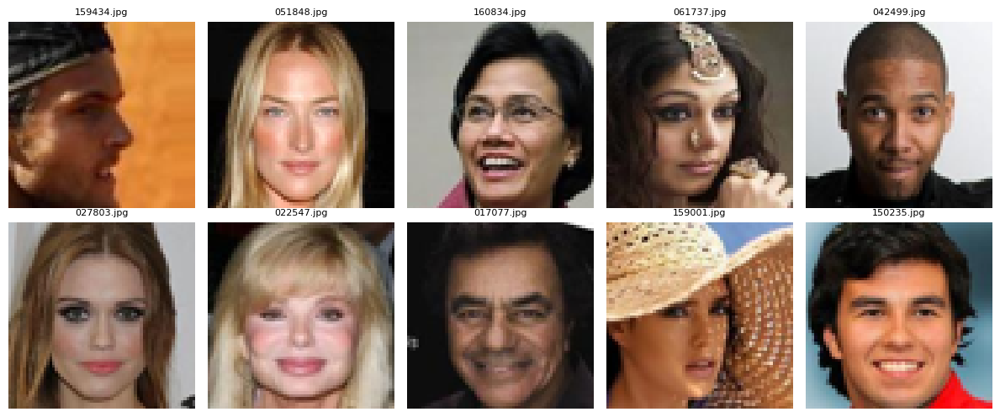

In [5]:
def show_images(images, titles=None, cols=5, figsize=(12, 8)):
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax, image, index in zip(axes.flat, images, range(len(images))):
        ax.imshow(np.clip(image, 0, 1))
        ax.axis("off")
        if titles is not None:
            ax.set_title(str(titles[index]), fontsize=8)
    for ax in axes.flat[len(images):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

sample_rng = np.random.default_rng(SEED)
sample_indices = sample_rng.choice(len(x_train), size=10, replace=False)
show_images(x_train[sample_indices], ids_train[sample_indices], cols=5, figsize=(12, 5))

---

## **3. Conjunto de pares de evaluación**

Hasta ahora evaluábamos el morphing con **un solo par** de caras elegido a mano, lo que no permite sacar conclusiones generales. El README del proyecto pide `20`-`30` pares **iguales para todos los métodos**, repartidos entre **fáciles** (pose y expresión similares) y **difíciles** (poses muy distintas). Construimos `24` pares, `12` de cada tipo, con una regla explícita y reproducible:

- **Pose.** CelebA no incluye la pose como atributo, pero sí las coordenadas de cinco *landmarks* (`list_landmarks_align_celeba.csv`). Usamos como indicador del giro de la cabeza (*yaw*) la posición horizontal de la nariz respecto al punto medio de los ojos, dividida por la distancia entre ojos: $\text{yaw} = (x_{nariz} - x_{medio\ ojos}) / (x_{ojo\ dcho} - x_{ojo\ izq})$. Vale `≈ 0` en una cara frontal y se aleja de `0` al girar la cabeza. Es una aproximación sencilla, no una medida exacta de la pose.
- **Pares fáciles:** mismo sexo (`Male`), misma expresión (`Smiling`), mismo grupo de color de pelo (negro, rubio, castaño, canoso u otro), **sin gafas ni sombrero** en ninguna de las dos, y diferencia de *yaw* de a lo sumo `0.08`.
- **Pares difíciles:** sexo distinto y diferencia de *yaw* de al menos `0.30`.
- **Reglas comunes:** todas las imágenes salen de `test`, **ninguna se repite** entre pares y se excluyen las `2000` primeras de `test`, que usamos como imágenes reconstruidas y como referencia del FID, para que los extremos de los pares no formen parte de la referencia del FID de los fotogramas.

Los pares se guardan en `data/processed/eval_pairs.json` **como identificadores de imagen** (por ejemplo `182638.jpg`), no como índices, de modo que el morphing clásico y la DCGAN puedan cargar las mismas caras desde `data/img_align_celeba` en su resolución original. Si el fichero ya existe, se reutiliza tal cual (así nadie cambia sin querer los pares); para regenerarlos hay que borrarlo.

In [6]:
PAIRS_PATH = PROCESSED_DIR / "eval_pairs.json"
LANDMARKS_PATH = PROCESSED_DIR.parent / "list_landmarks_align_celeba.csv"
ID_TO_INDEX = {str(image_id): index for index, image_id in enumerate(ids_test)}


def yaw_proxy(ids):
    landmarks = pd.read_csv(LANDMARKS_PATH).set_index("image_id").loc[[str(i) for i in ids]]
    eyes_middle = (landmarks.lefteye_x + landmarks.righteye_x) / 2.0
    eyes_distance = landmarks.righteye_x - landmarks.lefteye_x
    return ((landmarks.nose_x - eyes_middle) / eyes_distance).to_numpy()


def build_eval_pairs(n_per_type, seed):
    yaw = yaw_proxy(ids_test)
    flag = lambda name: attrs_test[:, ATTR_NAMES.index(name)] == 1
    male, smiling = flag("Male"), flag("Smiling")
    hair = np.select(
        [flag("Black_Hair"), flag("Blond_Hair"), flag("Brown_Hair"), flag("Gray_Hair")], [0, 1, 2, 3], default=4
    )
    clean = ~flag("Eyeglasses") & ~flag("Wearing_Hat")
    # Excluimos las primeras 2 * FID_REAL_SAMPLES imágenes (usadas en el FID de reconstrucción y de referencia).
    available = np.arange(len(ids_test)) >= 2 * FID_REAL_SAMPLES
    used = np.zeros(len(ids_test), dtype=bool)
    rng = np.random.default_rng(seed)
    pairs = []

    def pick(kind, partner_mask):
        found = 0
        for a in rng.permutation(len(ids_test)):
            if found >= n_per_type:
                break
            if used[a] or not available[a] or (kind == "fácil" and not clean[a]):
                continue
            mask = partner_mask(a) & available & ~used
            mask[a] = False
            candidates = np.flatnonzero(mask)
            if len(candidates) == 0:
                continue
            b = int(rng.choice(candidates))
            used[a] = used[b] = True
            pairs.append({
                "type": kind,
                "a": str(ids_test[a]), "b": str(ids_test[b]),
                "yaw_a": round(float(yaw[a]), 3), "yaw_b": round(float(yaw[b]), 3),
            })
            found += 1
        if found < n_per_type:
            raise RuntimeError(f"Solo se encontraron {found} pares {kind}s de {n_per_type}")

    pick("fácil", lambda a: clean & (male == male[a]) & (smiling == smiling[a]) & (hair == hair[a])
         & (np.abs(yaw - yaw[a]) <= 0.08))
    pick("difícil", lambda a: (male != male[a]) & (np.abs(yaw - yaw[a]) >= 0.30))
    return pairs


if PAIRS_PATH.exists():
    EVAL_PAIRS = json.loads(PAIRS_PATH.read_text())
    origin = "cargados de"
else:
    EVAL_PAIRS = build_eval_pairs(N_PAIRS_PER_TYPE, SEED)
    PAIRS_PATH.write_text(json.dumps(EVAL_PAIRS, indent=2, ensure_ascii=False))
    origin = "creados y guardados en"
missing_ids = [p[k] for p in EVAL_PAIRS for k in ("a", "b") if p[k] not in ID_TO_INDEX]
if missing_ids:
    raise ValueError(f"Hay pares con imágenes que no están en test: {missing_ids[:5]}")

PAIR_A = np.array([ID_TO_INDEX[p["a"]] for p in EVAL_PAIRS])
PAIR_B = np.array([ID_TO_INDEX[p["b"]] for p in EVAL_PAIRS])
PAIR_TYPES = np.array([p["type"] for p in EVAL_PAIRS])
print(f"{len(EVAL_PAIRS)} pares {origin} {PAIRS_PATH.resolve()}")
print(f"Fáciles: {(PAIR_TYPES == 'fácil').sum()} | difíciles: {(PAIR_TYPES == 'difícil').sum()}")
yaw_gap = np.array([abs(p["yaw_a"] - p["yaw_b"]) for p in EVAL_PAIRS])
print(f"Diferencia de yaw media: fáciles {yaw_gap[PAIR_TYPES == 'fácil'].mean():.2f} | "
      f"difíciles {yaw_gap[PAIR_TYPES == 'difícil'].mean():.2f}")

24 pares cargados de /home/sanru/Escritorio/7_cuatri/PCD/project/morphing/data/processed/eval_pairs.json
Fáciles: 12 | difíciles: 12
Diferencia de yaw media: fáciles 0.05 | difíciles 0.53


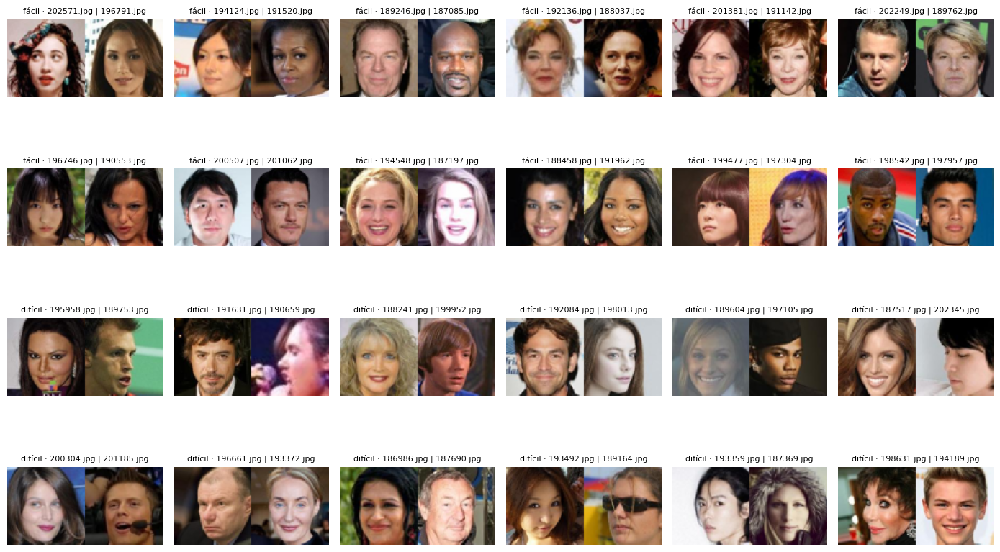

In [7]:
# Los pares, de dos en dos (A | B), agrupados por tipo.
pair_images = [np.concatenate([x_test[a], x_test[b]], axis=1) for a, b in zip(PAIR_A, PAIR_B)]
pair_titles = [f"{p['type']} · {p['a']} | {p['b']}" for p in EVAL_PAIRS]
show_images(pair_images, pair_titles, cols=6, figsize=(14, 9))

---

## **4. Encoder, decoder, VAE y función de pérdida**

El modelo es **el mismo de `VAE_complex1`** (a su vez el de `AE_complex2_VGG`, sin bloques residuales) y la única diferencia es que ahora se construye con una **función** que recibe la dimensión latente, para poder crear los modelos de cada experimento:

- **Encoder:** cuatro convoluciones `4x4` con `stride=2` (`32, 64, 128, 256` filtros) con `BatchNormalization` y `LeakyReLU`; dos cabezas densas `z_mean` y `z_log_var` de tamaño `z`; y el muestreo con reparametrización $z = \mu + \sigma \odot \varepsilon$. Devuelve `[z_mean, z_log_var, z]`.
- **Decoder:** capa densa a `4x4x256`, cuatro bloques de sobremuestreo bilineal y convolución `3x3` (`256, 128, 64, 32`) y una convolución final con sigmoide.
- **Pérdida:**

$$\mathcal{L} = \underbrace{0.5\,L_1 + 0.5\,(1 - SSIM) + \lambda\, L_{VGG}}_{\mathcal{L}_{recon}} + \beta \cdot \frac{D_{KL}\big(q_\phi(z \mid x)\,\|\,\mathcal{N}(0, I)\big)}{12288}, \qquad \lambda = 10^{-4}$$

  con $D_{KL} = -\tfrac{1}{2} \sum_{j=1}^{z} (1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2)$ **sumada sobre las `z` dimensiones** (por tanto, con `z` más pequeño la KL máxima posible es menor) y `12288 = 64·64·3`. La justificación de esta pérdida y de la normalización está en la sección 4 de `VAE_complex1`.
- **Evaluación determinista:** para reconstruir y para el morphing usamos siempre `z_mean`, sin ruido.

**Qué esperamos de cada factor.** No lo damos por sabido, es lo que este notebook pone a prueba. La intuición habitual es que (1) con una dimensión latente pequeña la reconstrucción pierde detalle porque hay menos capacidad, pero el espacio queda más denso y regular; (2) con una `β` mayor el latente se acerca más al prior y la generación desde él mejora, a costa de reconstrucciones más borrosas, y con una `β` muy grande el codificador acaba ignorando la imagen (*posterior collapse*). Las conclusiones de la sección 10 dirán hasta qué punto se cumple esto **en nuestros datos**.

In [8]:
@keras.utils.register_keras_serializable(package="vae")
class Sampling(layers.Layer):
    """Truco de reparametrización: z = mu + sigma * epsilon."""

    def __init__(self, seed=SEED, **kwargs):
        super().__init__(**kwargs)
        self.seed = seed
        self.seed_generator = keras.random.SeedGenerator(seed)

    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = keras.random.normal(keras.ops.shape(z_mean), seed=self.seed_generator)
        return z_mean + keras.ops.exp(0.5 * z_log_var) * epsilon

    def get_config(self):
        config = super().get_config()
        config.update({"seed": self.seed})
        return config

    def compute_output_shape(self, input_shape):
        return input_shape[0]


def build_encoder(latent_dim):
    encoder_inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS), name="encoder_input")
    x = encoder_inputs
    for filters in (32, 64, 128, 256):
        x = layers.Conv2D(filters, kernel_size=4, strides=2, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.LeakyReLU(negative_slope=0.2)(x)
    x = layers.Flatten()(x)
    z_mean = layers.Dense(latent_dim, name="z_mean")(x)
    z_log_var = layers.Dense(latent_dim, name="z_log_var")(x)
    z = Sampling(name="z")([z_mean, z_log_var])
    return keras.Model(encoder_inputs, [z_mean, z_log_var, z], name="encoder_vae")


def build_decoder(latent_dim):
    decoder_inputs = keras.Input(shape=(latent_dim,), name="decoder_input")
    x = layers.Dense(4 * 4 * 256, use_bias=False)(decoder_inputs)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)
    x = layers.Reshape((4, 4, 256))(x)
    for filters in (256, 128, 64, 32):
        x = layers.UpSampling2D(size=(2, 2), interpolation="bilinear")(x)
        x = layers.Conv2D(filters, kernel_size=3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.LeakyReLU(negative_slope=0.2)(x)
    decoder_outputs = layers.Conv2D(
        CHANNELS, kernel_size=3, padding="same", activation="sigmoid", name="decoder_output"
    )(x)
    return keras.Model(decoder_inputs, decoder_outputs, name="decoder_vae")


# Resumen de las dimensiones extremas, para comprobar el tamaño de los modelos.
for _latent in (16, 256):
    _encoder, _decoder = build_encoder(_latent), build_decoder(_latent)
    print(f"z={_latent:>3}: encoder {_encoder.count_params():,} parámetros | decoder {_decoder.count_params():,} parámetros")
del _encoder, _decoder

I0000 00:00:1793954037.561787    5936 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2142 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


z= 16: encoder 822,688 parámetros | decoder 1,061,603 parámetros
z=256: encoder 2,789,248 parámetros | decoder 2,044,643 parámetros


In [9]:
def ssim_l1_loss(y_true, y_pred):
    l1 = tf.reduce_mean(tf.abs(y_true - y_pred))
    structural_loss = 1.0 - tf.reduce_mean(tf.image.ssim(y_true, y_pred, max_val=1.0))
    return 0.5 * l1 + 0.5 * structural_loss

LAMBDA = 1e-4
vgg = keras.applications.VGG16(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
)
vgg.trainable = False
LAYERS = ["block1_conv2", "block2_conv2"]
feat = keras.Model(vgg.input, [vgg.get_layer(name).output for name in LAYERS], name="vgg_features")
feat.trainable = False


def perceptual(y_true, y_pred):
    preprocess = lambda x: keras.applications.vgg16.preprocess_input(x * 255.0)
    true_features = feat(preprocess(y_true), training=False)
    pred_features = feat(preprocess(y_pred), training=False)
    return tf.add_n([
        tf.reduce_mean(tf.abs(true - pred))
        for true, pred in zip(true_features, pred_features)
    ])


def full_loss(y_true, y_pred):
    # Pérdida de reconstrucción de AE_complex2_VGG.
    return ssim_l1_loss(y_true, y_pred) + LAMBDA * perceptual(y_true, y_pred)


INPUT_DIM = IMG_SIZE * IMG_SIZE * CHANNELS


class VAE(keras.Model):
    def __init__(self, encoder, decoder, beta=1.0, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.beta = beta
        self.loss_tracker = keras.metrics.Mean(name="loss")
        self.recon_tracker = keras.metrics.Mean(name="recon_loss")
        self.kl_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [self.loss_tracker, self.recon_tracker, self.kl_tracker]

    def call(self, inputs):
        # Reconstrucción determinista (sin ruido), a través de z_mean.
        return self.decoder(self.encoder(inputs)[0])

    def compute_losses(self, x, training):
        z_mean, z_log_var, z = self.encoder(x, training=training)
        reconstruction = self.decoder(z, training=training)
        recon_loss = full_loss(x, reconstruction)
        # KL por imagen (suma sobre las dimensiones latentes) y media sobre el lote.
        kl_loss = tf.reduce_mean(
            -0.5 * tf.reduce_sum(1.0 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=-1)
        )
        total_loss = recon_loss + self.beta * kl_loss / INPUT_DIM
        return total_loss, recon_loss, kl_loss

    def _update_metrics(self, total_loss, recon_loss, kl_loss):
        self.loss_tracker.update_state(total_loss)
        self.recon_tracker.update_state(recon_loss)
        self.kl_tracker.update_state(kl_loss)
        return {metric.name: metric.result() for metric in self.metrics}

    def train_step(self, data):
        x = data[0] if isinstance(data, (tuple, list)) else data
        with tf.GradientTape() as tape:
            total_loss, recon_loss, kl_loss = self.compute_losses(x, training=True)
        gradients = tape.gradient(total_loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(gradients, self.trainable_variables))
        return self._update_metrics(total_loss, recon_loss, kl_loss)

    def test_step(self, data):
        x = data[0] if isinstance(data, (tuple, list)) else data
        total_loss, recon_loss, kl_loss = self.compute_losses(x, training=False)
        return self._update_metrics(total_loss, recon_loss, kl_loss)


INITIAL_LEARNING_RATE = 1e-3
MIN_LEARNING_RATE = 1e-5
# Keras cuenta los micro-pasos (no las actualizaciones reales) al evaluar la tasa de aprendizaje: DECAY_STEPS debe
# calcularse con el micro-lote o el Cosine Decay terminaría antes de tiempo (ver la nota técnica de la sección 5).
DECAY_STEPS = int(np.ceil(len(x_train) / MICRO_BATCH_SIZE) * EPOCHS)


def make_optimizer():
    # Un programa de tasa de aprendizaje nuevo por experimento: todos empiezan en 1e-3 y terminan en 1e-5.
    schedule = keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=INITIAL_LEARNING_RATE,
        decay_steps=DECAY_STEPS,
        alpha=MIN_LEARNING_RATE / INITIAL_LEARNING_RATE,
    )
    return keras.optimizers.Adam(learning_rate=schedule, gradient_accumulation_steps=ACCUMULATION_STEPS)

---

## **5. Entrenamiento y guardado**

Cada experimento se entrena **por separado** con la misma receta que `VAE_complex1` (solo `train`, validación con `val`, `30` épocas como máximo, `EarlyStopping` con paciencia `6`, la misma semilla, un `Cosine Decay` nuevo de `1e-3` a `1e-5` y lote efectivo de `128`), con una **única diferencia de procedimiento: el lote de `128` se procesa en `2` micro-lotes de `64` con acumulación de gradientes** (nota técnica más abajo). Al terminar, guarda el encoder, el decoder y el historial (`loss`, `recon_loss`, `kl_loss` y el tiempo de cada época) con el mismo esquema de nombres que el resto de la serie (`encoder_<nombre>.keras`, `decoder_<nombre>.keras`, `<nombre>_history.json`).

El entrenamiento usa `verbose=2` (una línea por época) para no llenar el notebook de barras de progreso a lo largo de varios entrenamientos. **El coste total es alto**: son `5` entrenamientos de hasta `30` épocas cada uno, y cada época tardó unos **`100 s`** con la acumulación de gradientes de la sección siguiente (`≈ 50 min` por modelo y `≈ 4 h 10 min` los `5`). El tiempo de cada época queda registrado en el historial.

Después de entrenar (o de comprobar que ya existen), **todos los modelos se cargan desde disco**, también los que acaban de entrenarse, de manera que la evaluación usa siempre los artefactos guardados y se comporta igual en una primera ejecución y en las siguientes. Si falta algún experimento (porque no se ha entrenado todavía), se avisa y el resto del notebook evalúa solo los que existen.

### **Nota técnica: acumulación de gradientes (`gradient_accumulation_steps`)**

Es la **única diferencia de procedimiento respecto a `VAE_complex1`** y conviene entenderla bien: no cambia el modelo ni la pérdida, pero sí cómo se calcula cada actualización de los pesos. Es la misma técnica que usamos en `AE_complex3`.

**El problema.** El primer intento de entrenar con el lote de la serie (`128` imágenes de una vez) falló en la primera época con `ResourceExhaustedError: Out of memory while trying to allocate 1.42GiB`. El registro de TensorFlow muestra que su asignador de memoria dispone de unos **`2.09 GiB`** (de los `4 GB` de la GPU) y que, durante el primer paso, intenta reservar bloques de `1.4`-`1.6 GiB` de una sola vez, cuando lo realmente ocupado en ese momento era solo de `0.3`-`0.8 GiB`. Como el espacio libre queda fragmentado, esos bloques no caben. Ya habíamos visto el mismo límite de `2.09 GiB` en `VAE_complex1` y en `AE_complex3`, y no sabemos por qué TensorFlow no usa más memoria. Tampoco hemos comprobado qué operación pide esos bloques (sospechamos de la compilación XLA que Keras activa por su cuenta, pero no lo hemos verificado).

**Por qué no simplemente bajar el `BATCH_SIZE`.** Entrenar con lote `64` daría el doble de actualizaciones por época, cada una con un gradiente más ruidoso, con la misma tasa de aprendizaje que `VAE_complex1`. Sería un experimento distinto y perdería validez la comparación con la referencia.

**La solución.** Procesamos **micro-lotes de `64` imágenes** y dejamos que el optimizador **acumule** los gradientes de `2` micro-lotes consecutivos; solo entonces actualiza los pesos con la media de ambos (`Adam(gradient_accumulation_steps=2)`). Como la pérdida es una media por imagen, el gradiente medio de `2` micro-lotes de `64` es el mismo que el de un lote de `128`: **el lote efectivo sigue siendo `128`**, igual que la tasa de aprendizaje y el número de actualizaciones por época (`≈ 469`). Los bloques que reserva TensorFlow dependen del tamaño del lote, así que con micro-lotes de `64` esperamos que se reduzcan aproximadamente a la mitad.

**Qué hemos verificado.** En el notebook de `AE_complex3` comprobamos con un modelo pequeño en CPU que un paso con lote `128` y uno con micro-lotes acumulados dan los mismos pesos (diferencia máxima `~1e-10`, con SGD y con Adam) y cómo cuenta los pasos el programador de la tasa de aprendizaje. **En la GPU de 4 GB funcionó:** con micro-lotes de `64` (`ACCUMULATION_STEPS = 2`) los `5` entrenamientos de `30` épocas se completaron sin errores de memoria, así que no hizo falta bajar a micro-lotes de `32`. Eso sí, en la evaluación (secciones 7 y 8) tuvimos que reducir el tamaño de lote de `predict` de `256` a `64`, porque tras los entrenamientos el asignador de memoria de la GPU quedaba fragmentado.

**Precauciones y diferencias que sí existen:**

1. **`DECAY_STEPS` se calcula con micro-pasos.** Keras evalúa el programador de la tasa de aprendizaje con el contador de micro-pasos y no con el de actualizaciones reales. Si se calculara con `BATCH_SIZE`, el `Cosine Decay` terminaría a la mitad del entrenamiento. Por eso `DECAY_STEPS` usa `MICRO_BATCH_SIZE` (`938` micro-pasos por época en lugar de `469`).
2. **`BatchNormalization` ve `64` imágenes y no `128`.** Calcula sus estadísticas con cada micro-lote, algo más ruidosas, y actualiza sus medias móviles el doble de veces. Es la única diferencia que la acumulación **no elimina**, y puede afectar ligeramente a los resultados. Afecta igual a los `5` modelos nuevos pero **no al de referencia** (`VAE_complex1`).
3. **Ventanas de acumulación.** Hay `938` micro-lotes por época (`937` de `64` imágenes y uno de `32`), un número par, así que cada actualización cubre dos micro-lotes de la misma época. La última de cada época promedia uno de `64` y uno de `32`, mientras que con lote real de `128` el último lote de la época tendría `96` imágenes: una diferencia mínima.
4. **Velocidad:** más pasos y más pequeños aprovechan peor la GPU. Medimos `≈ 100 s` por época; no tenemos la medida con lote real de `128`, porque no cabe.
5. **Reproducibilidad:** los resultados no serán idénticos bit a bit a los de un entrenamiento con lote `128` real, aunque estadísticamente son equivalentes salvo por el punto `2`.

### **Nota técnica: por qué entregamos los datos por lotes (`BatchSequence`)**

Igual que en `VAE_complex1`, no entrenamos con `fit(x_train)`, sino entregando los datos por lotes desde la RAM con una clase `BatchSequence`. La diferencia no afecta al modelo, solo a la memoria, y la explicación completa (copiada de `VAE_complex1`) es esta:

**El problema.** Al entrenar en una GPU de `4 GB` (RTX 3050 de portátil) el entrenamiento fallaba antes de empezar la primera época con:

```
InternalError: Failed copying input tensor from .../device:CPU:0 to .../device:GPU:0
in order to run _EagerConst: Dst tensor is not initialized.
```

Ese mensaje es, en la práctica, un *out of memory* de la GPU. No es un fallo de la arquitectura ni de la pérdida.

**La causa.** Cuando se le pasa a `fit` un array de NumPy, Keras lo incorpora **entero** como una constante de su canal de datos (`tf.data`), y si hay GPU esa constante se copia a la memoria de la GPU de una sola vez. Nuestro `x_train` ocupa `60000 × 64 × 64 × 3 × 4 bytes ≈ 2.95 GB` en `float32`. Sumado a lo que ya ocupan el modelo, la VGG16 y las activaciones, no cabe en `4 GB`. Aunque la GPU estuviera vacía, iría al límite. En una GPU con más memoria el problema no aparecería; es de esperar que por eso los notebooks anteriores no lo necesiten, aunque no hemos comprobado con qué GPU se entrenaron.

**La solución.** Una clase `BatchSequence` (un `keras.utils.PyDataset`) que **mantiene las imágenes en la RAM del ordenador** y entrega a Keras un lote de `128` imágenes cada vez. A la GPU solo llega un lote (`128 × 64 × 64 × 3 × 4 bytes ≈ 6 MB`) en cada paso, en lugar de las `60000` imágenes a la vez. Se usa igual para `val`.

**Qué cambia y qué no:**

- **No cambia** el modelo, la pérdida, el optimizador, el `Cosine Decay`, el tamaño de lote ni las épocas. Cada paso de entrenamiento procesa un lote de `128` imágenes, como antes.
- **Barajado:** `fit(x_train)` baraja las imágenes en cada época. `BatchSequence(shuffle=True)` hace lo mismo (baraja al crearse y al final de cada época) con un generador de números aleatorios con semilla fija (`SEED`), de modo que el orden es reproducible. Esto es importante porque `train` está ordenado por identificador de imagen: sin barajar, la primera época vería las imágenes en el orden del fichero. **No será exactamente el mismo orden** que con `fit(x_train)`, así que los resultados no serán idénticos bit a bit a los de un entrenamiento hecho con la otra forma, aunque estadísticamente son equivalentes.
- **Coste:** hay un pequeño trabajo extra de CPU para preparar cada lote (seleccionar `128` imágenes del array). No lo hemos medido, pero cabe esperar que sea pequeño frente al tiempo de cálculo en la GPU.

**Cuándo hace falta.** Solo si el conjunto de entrenamiento no cabe cómodamente en la memoria de la GPU. No hay que cambiar los notebooks anteriores: funcionan bien con su `fit(x_train, x_train)` en una GPU con memoria suficiente. En `float32` y RGB, el conjunto de `train` es el elemento más grande en memoria; en escala de grises (un canal) ocuparía un tercio.

**Alternativas que no hemos usado (y no hemos probado):** convertir `x_train` a `float16` (cambia la precisión de los datos de entrada) o mantenerlo en `uint8` y normalizar dentro del modelo (cambia la estructura del modelo respecto a la serie). Reducir el `BATCH_SIZE` no resolvería este error en concreto, porque lo que se copia a la GPU es el conjunto entero y no un lote.

In [10]:
class BatchSequence(keras.utils.PyDataset):
    """Entrega los lotes desde la RAM. Evita que fit(x_train) copie el conjunto entero (~3 GB) a la GPU."""

    def __init__(self, images, batch_size, shuffle=False, seed=SEED, **kwargs):
        super().__init__(**kwargs)
        self.images = images
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.rng = np.random.default_rng(seed)
        self.indices = np.arange(len(images))
        # train está ordenado por id: barajamos ya desde la primera época, como hace fit().
        if self.shuffle:
            self.rng.shuffle(self.indices)

    def __len__(self):
        return int(np.ceil(len(self.images) / self.batch_size))

    def __getitem__(self, index):
        batch_indices = self.indices[index * self.batch_size:(index + 1) * self.batch_size]
        return self.images[batch_indices]

    def on_epoch_end(self):
        # Y volvemos a barajar al final de cada época, como hace fit() con shuffle=True.
        if self.shuffle:
            self.rng.shuffle(self.indices)


class EpochTimer(keras.callbacks.Callback):
    """Guarda cuánto tarda cada época (para el apartado de coste)."""

    def on_train_begin(self, logs=None):
        self.seconds = []

    def on_epoch_begin(self, epoch, logs=None):
        self._start = time.time()

    def on_epoch_end(self, epoch, logs=None):
        self.seconds.append(time.time() - self._start)


def train_experiment(experiment):
    keras.utils.set_random_seed(SEED)
    encoder = build_encoder(experiment["latent"])
    decoder = build_decoder(experiment["latent"])
    vae = VAE(encoder, decoder, beta=experiment["beta"], name="vae")
    vae.compile(optimizer=make_optimizer())
    timer = EpochTimer()
    # Entrenamos con train y usamos val únicamente para seleccionar el mejor estado.
    history = vae.fit(
        BatchSequence(x_train, MICRO_BATCH_SIZE, shuffle=True),
        epochs=EPOCHS,
        validation_data=BatchSequence(x_val, MICRO_BATCH_SIZE),
        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True), timer],
        verbose=2,
    )
    encoder_path, decoder_path, history_path = artifact_paths(experiment["name"])
    encoder.save(encoder_path)
    decoder.save(decoder_path)
    saved = {key: [float(value) for value in values] for key, values in history.history.items()}
    saved["epoch_seconds"] = [float(value) for value in timer.seconds]
    history_path.write_text(json.dumps(saved, indent=2))
    del vae, encoder, decoder
    gc.collect()


for experiment in EXPERIMENTS:
    paths = artifact_paths(experiment["name"])
    exists = all(path.exists() for path in paths)
    selected = RUN_ONLY is None or experiment["name"] in RUN_ONLY
    if exists and not (FORCE_RETRAIN and selected and experiment["trainable"]):
        print(f"[ya existe] {experiment['name']} ({label(experiment)})")
        continue
    if not experiment["trainable"]:
        print(f"[AVISO] Faltan los checkpoints de {experiment['name']} (modelo de VAE_complex1): se omite.")
        continue
    if not TRAIN_MODEL or not selected:
        print(f"[pendiente] {experiment['name']} ({label(experiment)}): no se entrena (TRAIN_MODEL/RUN_ONLY).")
        continue
    print(f"\n=== Entrenando {experiment['name']} ({label(experiment)}) ===")
    train_experiment(experiment)
    print(f"[guardado] {experiment['name']}")

[ya existe] vae_complex2_z32_b1 (z=32, β=1)
[ya existe] vae_complex2_z16_b1 (z=16, β=1)
[ya existe] vae_complex2_z64_b1 (z=64, β=1)
[ya existe] vae_complex2_z32_b0p5 (z=32, β=0.5)
[ya existe] vae_complex2_z32_b2 (z=32, β=2)
[ya existe] vae_complex1_latent256 (z=256, β=1)


In [11]:
# Carga de todos los modelos disponibles (también los recién entrenados) y de sus historiales.
MODELS = {}
for experiment in EXPERIMENTS:
    encoder_path, decoder_path, history_path = artifact_paths(experiment["name"])
    if not all(path.exists() for path in (encoder_path, decoder_path, history_path)):
        print(f"[sin checkpoints] {experiment['name']}: no se evaluará")
        continue
    MODELS[experiment["name"]] = {
        "encoder": keras.models.load_model(encoder_path),
        "decoder": keras.models.load_model(decoder_path),
        "history": json.loads(history_path.read_text()),
    }
READY = [experiment for experiment in EXPERIMENTS if experiment["name"] in MODELS]
if not READY:
    raise RuntimeError("No hay ningún experimento entrenado: pon TRAIN_MODEL = True y vuelve a ejecutar.")
print(f"Experimentos disponibles ({len(READY)}): " + ", ".join(label(e) for e in READY))

Experimentos disponibles (6): z=32, β=1, z=16, β=1, z=64, β=1, z=32, β=0.5, z=32, β=2, z=256, β=1


In [12]:
# Resumen del entrenamiento de cada experimento.
training_rows = []
for experiment in READY:
    history = MODELS[experiment["name"]]["history"]
    best = int(np.argmin(history["val_loss"]))
    seconds = history.get("epoch_seconds")
    kl_weight = experiment["beta"] * history["val_kl_loss"][best] / INPUT_DIM
    training_rows.append({
        "experimento": label(experiment),
        "grupo": experiment["group"],
        "épocas": len(history["val_loss"]),
        "mejor época": best + 1,
        "val recon_loss": history["val_recon_loss"][best],
        "val KL (nats)": history["val_kl_loss"][best],
        "peso KL en la pérdida (%)": 100.0 * kl_weight / history["val_loss"][best],
        "s/época": float(np.mean(seconds)) if seconds else np.nan,
    })
training_df = pd.DataFrame(training_rows).set_index("experimento")
display(training_df.round(4))

,grupo,épocas,mejor época,val recon_loss,val KL (nats),peso KL en la pérdida (%),s/época
experimento,,,,,,,
"z=32, β=1",base,30,30,0.2270,90.1281,3.1298,100.5032
"z=16, β=1",latente,30,29,0.2665,51.3093,1.5429,98.9097
"z=64, β=1",latente,30,30,0.1895,154.5502,6.2250,99.8476
"z=32, β=0.5",beta,30,30,0.2266,102.0644,1.8001,99.6316
"z=32, β=2",beta,30,30,0.2286,78.1446,5.2715,99.6789
"z=256, β=1",referencia,30,30,0.1338,350.1586,17.5611,NaN


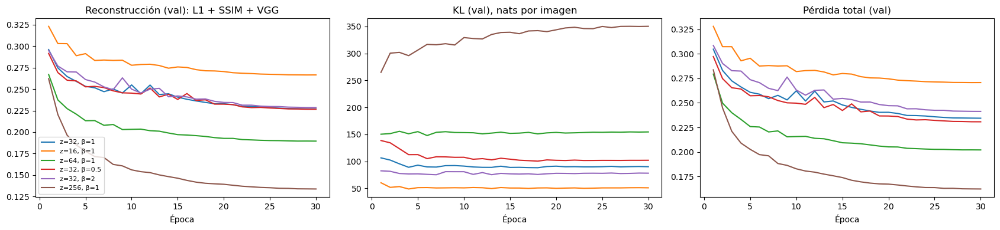

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for experiment in READY:
    history = MODELS[experiment["name"]]["history"]
    for ax, key in zip(axes, ("val_recon_loss", "val_kl_loss", "val_loss")):
        ax.plot(range(1, len(history[key]) + 1), history[key], label=label(experiment))
for ax, title in zip(axes, ("Reconstrucción (val): L1 + SSIM + VGG", "KL (val), nats por imagen", "Pérdida total (val)")):
    ax.set_title(title)
    ax.set_xlabel("Época")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Resultados del entrenamiento.** Los `5` modelos completaron las `30` épocas y `EarlyStopping` no llegó a detener ninguno; la mejor época es la última (`30`) en cuatro de ellos y la `29` en `z = 16`, es decir, **todos seguían mejorando muy despacio al acabar** (la tasa de aprendizaje ya estaba en `~1e-5`), y no sabemos cuánto habrían mejorado con más épocas.

| Modelo | `recon_loss` (val) | KL (val, nats) | Peso de la KL en la pérdida |
| --- | --- | --- | --- |
| `z=16, β=1` | `0.2665` | `51.3` | `1.5 %` |
| `z=32, β=0.5` | `0.2266` | `102.1` | `1.8 %` |
| `z=32, β=1` | `0.2270` | `90.1` | `3.1 %` |
| `z=32, β=2` | `0.2286` | `78.1` | `5.3 %` |
| `z=64, β=1` | `0.1895` | `154.6` | `6.2 %` |
| `z=256, β=1` (`VAE_complex1`) | `0.1338` | `350.2` | `17.6 %` |

- **Sin *posterior collapse*.** La KL de ningún modelo se acerca a cero: se estabiliza en una cifra que depende de `z` y de `β` (curvas de la figura) y el encoder sigue usando la imagen en todos.
- **Efecto de `β` (`z = 32`).** Duplicar `β` baja la KL unos `12` nats cada vez (`102 → 90 → 78`), y la `recon_loss` apenas sube (`0.2266 → 0.2270 → 0.2286`, un `0.9 %` en total). Con esta normalización, el término KL pesa solo entre un `1.8 %` y un `5.3 %` de la pérdida para `β = 0.5`-`2`, así que **el barrido recorre un rango estrecho** y no es de extrañar que el efecto sea pequeño.
- **Efecto de `z` (`β = 1`).** Aquí sí hay un cambio claro y ordenado: la `recon_loss` baja de `0.2665` (`z = 16`) a `0.2270` (`32`), `0.1895` (`64`) y `0.1338` (`256`), y la KL sube de `51` a `351` nats. A más dimensiones, el peso relativo de la KL crece (de `1.5 %` a `17.6 %`).
- **Sin sobreajuste visible.** En los `5` modelos nuevos `loss` y `val_loss` terminan casi juntos (por ejemplo, `z = 32`, `β = 1`: `0.2328` frente a `0.2343`).
- **Cuidado al comparar:** `loss` total **no es comparable** entre modelos con distinta `β`; para la calidad de reconstrucción hay que usar `recon_loss`. Y el modelo de `z = 256` se entrenó con lote real de `128` y los demás con acumulación de gradientes (sección 5), así que su diferencia con el resto mezcla el efecto de `z` con ese cambio de procedimiento.
- **Tiempo:** `≈ 100 s` por época en todos (`99`-`101 s`), es decir, `≈ 50 min` por modelo. `z` no cambia el coste.

---

## **6. Reconstrucciones en test**

Para cada modelo calculamos, sobre **todo el conjunto `test`** (`10000` imágenes) y con `z_mean` (sin ruido), el **MSE** y el **SSIM** entre cada imagen y su reconstrucción, y el **FID de reconstrucción** con el protocolo de siempre: `1000` reconstrucciones de `test` frente a `1000` imágenes reales distintas de `test`. MSE y SSIM miden la fidelidad píxel a píxel (penalizan una reconstrucción plausible pero distinta de la original); el FID mide si la distribución de reconstrucciones se parece a la de caras reales. Pueden dar órdenes distintos, como ya vimos en la serie.

El FID de reconstrucción de `VAE_complex1` fue `61.57` y el del autoencoder `AE_complex2_VGG`, `61.17`. Las reconstrucciones están en RGB y por tanto los FID **sí son comparables** con los de la serie RGB, a diferencia de `AE_complex3`.

In [14]:
# FID de reconstrucciones: mismo protocolo que en el resto de la serie.
FID_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FID_BATCH_SIZE = 32


def prepare_images_for_fid(images):
    images = np.asarray(images)
    if images.ndim == 3:
        images = images[..., np.newaxis]
    if images.ndim != 4 or images.shape[-1] not in (1, 3):
        raise ValueError(f"Se esperaban imágenes con forma (N, H, W, 1|3); recibidas {images.shape}")
    if images.dtype != np.uint8:
        images = np.clip(images, 0.0, 1.0)
        images = (images * 255.0).round().astype(np.uint8)
    if images.shape[-1] == 1:
        images = np.repeat(images, 3, axis=-1)
    images = np.transpose(images, (0, 3, 1, 2))
    return torch.from_numpy(np.ascontiguousarray(images))


def calculate_fid(generated_images, real_images, batch_size=FID_BATCH_SIZE):
    generated_images = prepare_images_for_fid(generated_images)
    real_images = prepare_images_for_fid(real_images)
    fid = FrechetInceptionDistance(feature=2048, normalize=False).to(FID_DEVICE)
    with torch.inference_mode():
        for start in range(0, len(real_images), batch_size):
            fid.update(real_images[start:start + batch_size].to(FID_DEVICE), real=True)
        for start in range(0, len(generated_images), batch_size):
            fid.update(generated_images[start:start + batch_size].to(FID_DEVICE), real=False)
    # El cálculo final (raíz de la matriz de covarianzas) se hace en la CPU: si TensorFlow y PyTorch comparten
    # proceso, cuSOLVER de PyTorch puede fallar con CUSOLVER_STATUS_INTERNAL_ERROR. Las características de
    # Inception ya se han calculado en la GPU, así que esto solo mueve unas pocas matrices.
    fid = fid.cpu()
    return float(fid.compute().item())


FID_REFERENCE = x_test[FID_REAL_SAMPLES:2 * FID_REAL_SAMPLES]


# Lotes de 64 al predecir: tras los entrenamientos el asignador de la GPU (2.09 GiB) queda fragmentado y con lotes
# de 256 se agotaba la memoria en la sección 8.
def encode_mean(name, images, batch_size=64):
    # Usamos la media μ(x) como código de la imagen: reconstrucción determinista.
    return MODELS[name]["encoder"].predict(images, batch_size=batch_size, verbose=0)[0]


def decode(name, latents, batch_size=64):
    return MODELS[name]["decoder"].predict(latents, batch_size=batch_size, verbose=0)

In [15]:
RESULTS = {experiment["name"]: {} for experiment in READY}
RECON_FIRST = {}          # primeras reconstrucciones de test (para las figuras)
CHUNK = 1000

for experiment in READY:
    name = experiment["name"]
    squared_error, ssim_sum = 0.0, 0.0
    for start in range(0, len(x_test), CHUNK):
        originals = x_test[start:start + CHUNK]
        reconstructions = decode(name, encode_mean(name, originals))
        squared_error += float(((originals - reconstructions) ** 2).sum())
        ssim_sum += float(tf.reduce_sum(tf.image.ssim(originals, reconstructions, max_val=1.0)))
        if start == 0:
            RECON_FIRST[name] = reconstructions
    RESULTS[name]["MSE"] = squared_error / x_test.size
    RESULTS[name]["SSIM"] = ssim_sum / len(x_test)
    RESULTS[name]["FID reconstrucción"] = calculate_fid(RECON_FIRST[name][:FID_REAL_SAMPLES], FID_REFERENCE)
    print(f"{label(experiment):>14}: MSE {RESULTS[name]['MSE']:.5f} | SSIM {RESULTS[name]['SSIM']:.4f} | "
          f"FID de reconstrucción {RESULTS[name]['FID reconstrucción']:.2f}")

I0000 00:00:1793954040.815478   11657 service.cc:153] XLA service 0x78e750030dc0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793954040.815495   11657 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 Laptop GPU, Compute Capability 8.6 (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.25.1)
I0000 00:00:1793954040.843674   11657 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793954040.907389   11657 cuda_dnn.cc:461] Loaded cuDNN version 92501
I0000 00:00:1793954040.940289   11657 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_4021__.1
I0000 00:00:1793954043.950517   11657 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
I0000 00:00:1793954044.116218   11657 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_4276

     z=32, β=1: MSE 0.01215 | SSIM 0.6744 | FID de reconstrucción 92.08


I0000 00:00:1793954071.150398   11656 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_12580__.1
I0000 00:00:1793954072.636178   11658 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_12835__.1


     z=16, β=1: MSE 0.01810 | SSIM 0.6167 | FID de reconstrucción 97.12


I0000 00:00:1793954092.741174   11658 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_21139__.1
I0000 00:00:1793954094.616947   11658 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_21394__.1


     z=64, β=1: MSE 0.00870 | SSIM 0.7354 | FID de reconstrucción 85.53


... (2 outputs left out)

I0000 00:00:1793954138.816405   11657 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_38257__.1
I0000 00:00:1793954139.692262   11656 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_38512__.1


     z=32, β=2: MSE 0.01214 | SSIM 0.6739 | FID de reconstrucción 91.77


I0000 00:00:1793954160.375942   11655 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_46816__.1
I0000 00:00:1793954160.803162   16587 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot', 32 bytes spill stores, 24 bytes spill loads

I0000 00:00:1793954162.193040   11655 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_47071__.1


    z=256, β=1: MSE 0.00463 | SSIM 0.8330 | FID de reconstrucción 61.57


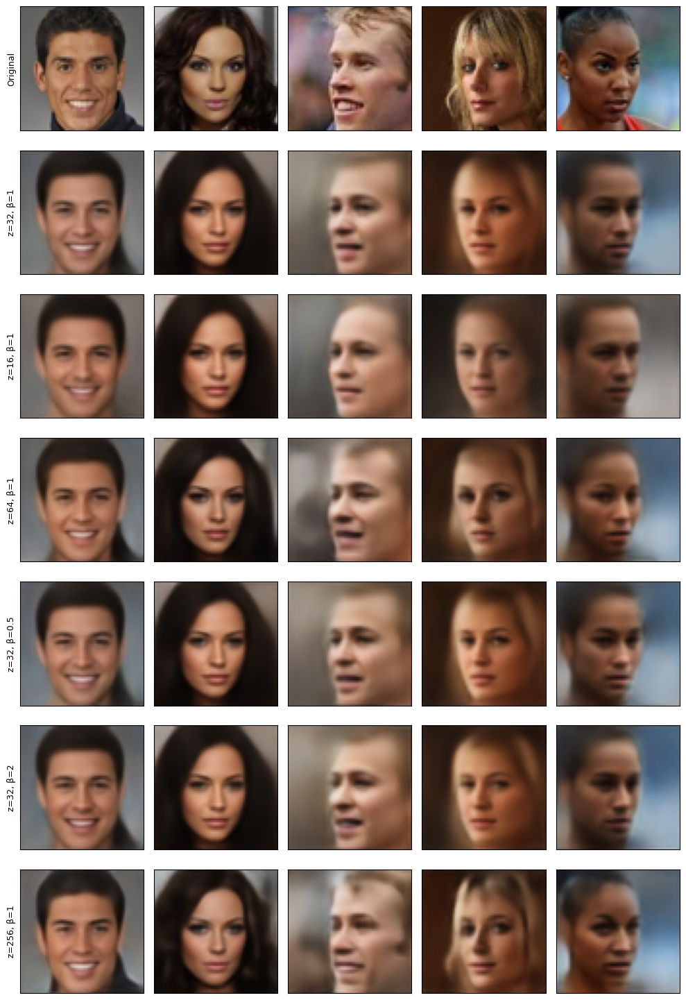

In [16]:
# Mismas imágenes de test para todos los modelos: la fila superior es el original.
sample_rng = np.random.default_rng(SEED)
visual_indices = sample_rng.choice(FID_REAL_SAMPLES, size=5, replace=False)
rows = [x_test[visual_indices]] + [RECON_FIRST[e["name"]][visual_indices] for e in READY]
row_labels = ["Original"] + [label(e) for e in READY]

fig, axes = plt.subplots(len(rows), 5, figsize=(10, 2.1 * len(rows)), squeeze=False)
for row_index, (row_images, row_label) in enumerate(zip(rows, row_labels)):
    for column, image in enumerate(row_images):
        axes[row_index, column].imshow(np.clip(image, 0, 1))
        axes[row_index, column].set_xticks([])
        axes[row_index, column].set_yticks([])
    axes[row_index, 0].set_ylabel(row_label, fontsize=9)
plt.tight_layout()
plt.show()

**Resultados** (todo `test`, `z_mean` sin ruido; FID con `1000` frente a `1000` imágenes):

| Modelo | MSE | SSIM | FID reconstrucción |
| --- | --- | --- | --- |
| `z=16, β=1` | `0.0181` | `0.617` | `97.12` |
| `z=32, β=1` | `0.0121` | `0.674` | `92.08` |
| `z=32, β=0.5` | `0.0122` | `0.674` | `93.28` |
| `z=32, β=2` | `0.0121` | `0.674` | `91.77` |
| `z=64, β=1` | `0.0087` | `0.735` | `85.53` |
| `z=256, β=1` | `0.0046` | `0.833` | `61.57` |

- **La dimensión latente importa mucho.** MSE, SSIM y FID mejoran de forma monótona con `z`, y los tres ordenan los modelos igual: `16 < 32 < 64 < 256`. Entre `z = 16` y `z = 64` el MSE casi se divide por dos y el FID baja `11.6` puntos, claramente por encima del ruido de la métrica. El salto de `64` a `256` es el mayor (`−24` puntos de FID), pero no lo podemos atribuir solo a `z`: el modelo de `256` se entrenó con lote real y los demás con acumulación de gradientes. No hemos comprobado cuánto pesa ese cambio de procedimiento; la diferencia es grande, y es plausible que gran parte sea efecto de `z`, pero no está demostrado.
- **`β` no se nota en la reconstrucción.** Con `z = 32`, el MSE y el SSIM de `β = 0.5`, `1` y `2` son prácticamente idénticos y el FID varía `1.5` puntos sin orden claro (`93.28`, `92.08`, `91.77`), dentro del ruido.
- **Aspecto visual** (figura): `z = 16` y `z = 32` conservan la pose, el color de la piel y el pelo y la expresión general, pero dan caras **muy borrosas**, sin detalle en ojos, pelo ni dientes; con `z = 64` se recuperan algo mejor los rasgos (ojos, boca, forma de la barbilla); `z = 256` es claramente el más nítido y conserva texturas, mechones de pelo y pendientes, aunque sigue borroso respecto a la original. Entre los tres valores de `β` a `z = 32` no vemos diferencias.
- **FID y MSE/SSIM coinciden** en el orden de los modelos en este experimento, a diferencia de lo que ocurrió en `AE_complex2`.
- **Comparación con la serie:** ningún modelo nuevo se acerca a los `61.17` de `AE_complex2_VGG` ni a los `61.57` del VAE de `256`; el mejor de los nuevos (`z = 64`) queda `24` puntos por encima.
- **Limitación:** una semilla por configuración, y el FID con `1000` imágenes tiene un ruido que no hemos medido.

---

## **7. Espacio latente y generación desde el prior**

### **7.1 Diagnóstico del espacio latente**

Para cada modelo medimos sobre `val`, igual que en `VAE_complex1`:

- **KL total** por imagen (en nats) y **KL por dimensión**, para ver cuánta información codifica el latente y si se reparte entre las dimensiones.
- **Dimensiones activas:** las que cumplen $\mathrm{Var}_x[\mu_j(x)] > 0.01$. Una dimensión «apagada» no aporta nada: el encoder devuelve para ella siempre la misma media. Si casi todas las dimensiones están activas, el latente es **demasiado pequeño para la información que el modelo quiere guardar** (el límite lo marca la dimensión, no la KL); si muchas están apagadas, el latente es más grande de lo necesario o la `β` es alta.
- **Norma media de $\mu$ frente a $\sqrt{z}$**, la norma típica de una muestra del prior $\mathcal{N}(0, I)$. Cuanto más se acerque, más parecida es la distribución de los códigos al prior.

### **7.2 Generación desde el prior**

Decodificamos `1000` muestras $z \sim \mathcal{N}(0, I)$ (con una semilla fija; la misma secuencia aleatoria, recortada, para cada dimensión) y calculamos su FID frente a la misma referencia de `test`. **No es comparable con el FID de reconstrucción** (generar es más difícil), pero es la medida directa de lo que la regularización aporta: un autoencoder determinista no puede generar desde el prior.

I0000 00:00:1793954185.885716   11657 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_4276__.1


     z=32, β=1: KL   90.12 nats | activas  32 de 32  | norma de μ 5.30 (prior: 5.66)


I0000 00:00:1793954188.152660   11656 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_12835__.1


     z=16, β=1: KL   51.31 nats | activas  16 de 16  | norma de μ 3.65 (prior: 4.00)


I0000 00:00:1793954189.728681   11658 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_21394__.1


     z=64, β=1: KL  154.56 nats | activas  64 de 64  | norma de μ 7.68 (prior: 8.00)


... (2 outputs left out)

I0000 00:00:1793954192.645162   11655 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_38512__.1


     z=32, β=2: KL   78.14 nats | activas  32 de 32  | norma de μ 5.34 (prior: 5.66)


I0000 00:00:1793954193.692811   11657 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_47071__.1


    z=256, β=1: KL  350.55 nats | activas 256 de 256 | norma de μ 14.92 (prior: 16.00)


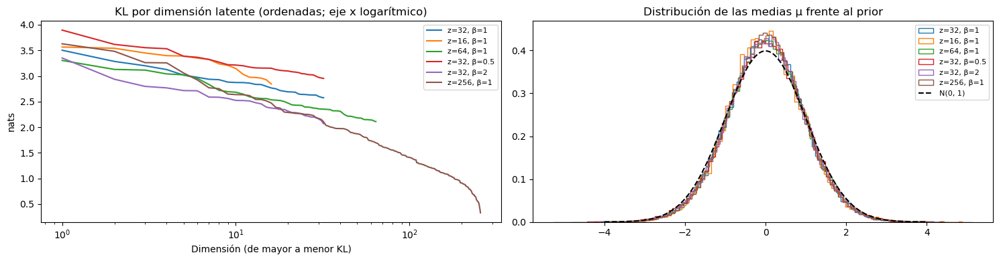

In [17]:
for experiment in READY:
    name, latent = experiment["name"], experiment["latent"]
    z_mean_val, z_log_var_val, _ = MODELS[name]["encoder"].predict(x_val, batch_size=64, verbose=0)
    kl_per_dim = (-0.5 * (1.0 + z_log_var_val - z_mean_val**2 - np.exp(z_log_var_val))).mean(axis=0)
    mean_variance = z_mean_val.var(axis=0)
    RESULTS[name]["KL total (nats)"] = float(kl_per_dim.sum())
    RESULTS[name]["dim. activas"] = int((mean_variance > 0.01).sum())
    RESULTS[name]["norma μ"] = float(np.linalg.norm(z_mean_val, axis=1).mean())
    RESULTS[name]["_kl_per_dim"] = np.sort(kl_per_dim)[::-1]
    RESULTS[name]["_mu_sample"] = z_mean_val[:2000].ravel()
    print(f"{label(experiment):>14}: KL {RESULTS[name]['KL total (nats)']:7.2f} nats | "
          f"activas {RESULTS[name]['dim. activas']:>3} de {latent:<3} | "
          f"norma de μ {RESULTS[name]['norma μ']:.2f} (prior: {np.sqrt(latent):.2f})")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for experiment in READY:
    name = experiment["name"]
    sorted_kl = RESULTS[name]["_kl_per_dim"]
    axes[0].plot(np.arange(1, len(sorted_kl) + 1), sorted_kl, label=label(experiment))
    axes[1].hist(RESULTS[name]["_mu_sample"], bins=100, density=True, histtype="step", label=label(experiment))
grid = np.linspace(-4, 4, 200)
axes[1].plot(grid, np.exp(-0.5 * grid**2) / np.sqrt(2 * np.pi), "k--", label="N(0, 1)")
axes[0].set_xscale("log")
axes[0].set_title("KL por dimensión latente (ordenadas; eje x logarítmico)")
axes[0].set_xlabel("Dimensión (de mayor a menor KL)")
axes[0].set_ylabel("nats")
axes[1].set_title("Distribución de las medias μ frente al prior")
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

     z=32, β=1: FID de generación desde el prior 102.69 (reconstrucción 92.08)
     z=16, β=1: FID de generación desde el prior 103.60 (reconstrucción 97.12)
     z=64, β=1: FID de generación desde el prior 98.19 (reconstrucción 85.53)
   z=32, β=0.5: FID de generación desde el prior 106.43 (reconstrucción 93.28)
     z=32, β=2: FID de generación desde el prior 101.20 (reconstrucción 91.77)
    z=256, β=1: FID de generación desde el prior 87.43 (reconstrucción 61.57)


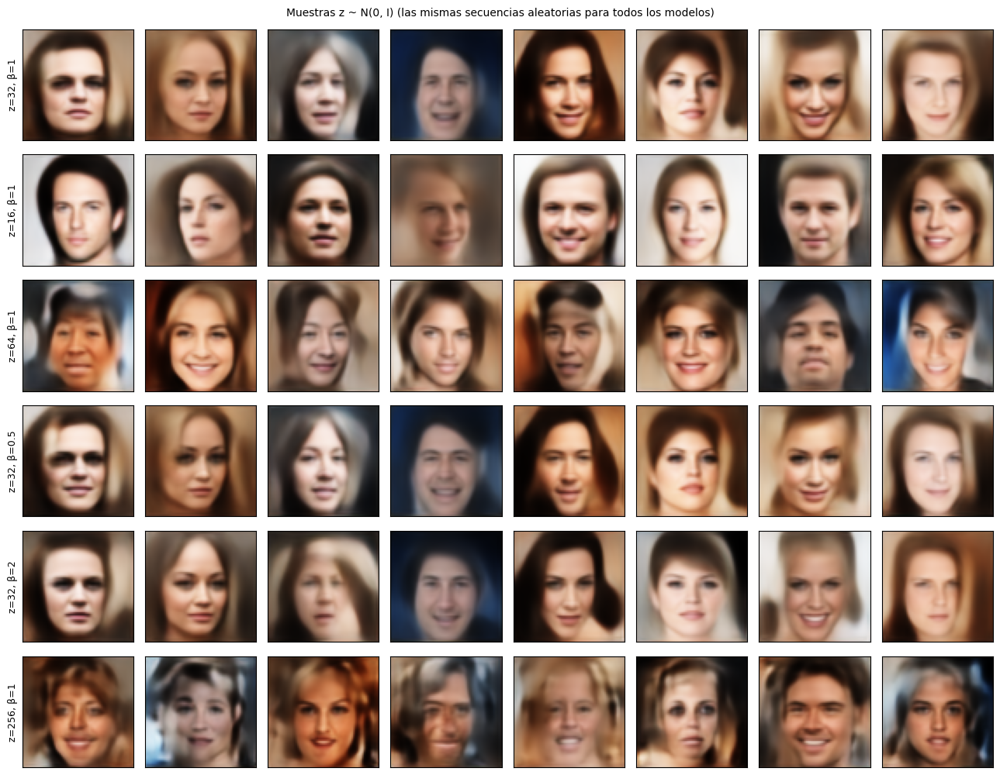

In [18]:
# Generación desde el prior. Misma secuencia aleatoria para todos los modelos (recortada a su dimensión).
prior_rng = np.random.default_rng(SEED)
prior_noise = prior_rng.standard_normal((FID_REAL_SAMPLES, max(e["latent"] for e in READY))).astype("float32")
GENERATED_FIRST = {}

for experiment in READY:
    name = experiment["name"]
    generated = decode(name, prior_noise[:, :experiment["latent"]])
    GENERATED_FIRST[name] = generated[:10]
    RESULTS[name]["FID prior"] = calculate_fid(generated, FID_REFERENCE)
    print(f"{label(experiment):>14}: FID de generación desde el prior {RESULTS[name]['FID prior']:.2f} "
          f"(reconstrucción {RESULTS[name]['FID reconstrucción']:.2f})")

fig, axes = plt.subplots(len(READY), 8, figsize=(13, 1.7 * len(READY)), squeeze=False)
for row, experiment in enumerate(READY):
    for column in range(8):
        axes[row, column].imshow(np.clip(GENERATED_FIRST[experiment["name"]][column], 0, 1))
        axes[row, column].set_xticks([])
        axes[row, column].set_yticks([])
    axes[row, 0].set_ylabel(label(experiment), fontsize=9)
plt.suptitle("Muestras z ~ N(0, I) (las mismas secuencias aleatorias para todos los modelos)", fontsize=10)
plt.tight_layout()
plt.show()

,MSE,SSIM,FID reconstrucción,FID prior,KL total (nats),dim. activas,norma μ
"z=32, β=1",0.0121,0.6744,92.0804,102.6865,90.1222,32.0,5.2950
"z=16, β=1",0.0181,0.6167,97.1167,103.5970,51.3112,16.0,3.6482
"z=64, β=1",0.0087,0.7354,85.5296,98.1873,154.5636,64.0,7.6848
"z=32, β=0.5",0.0122,0.6739,93.2781,106.4304,102.0612,32.0,5.4356
"z=32, β=2",0.0121,0.6739,91.7735,101.1992,78.1398,32.0,5.3418
"z=256, β=1",0.0046,0.8330,61.5706,87.4282,350.5544,256.0,14.9156


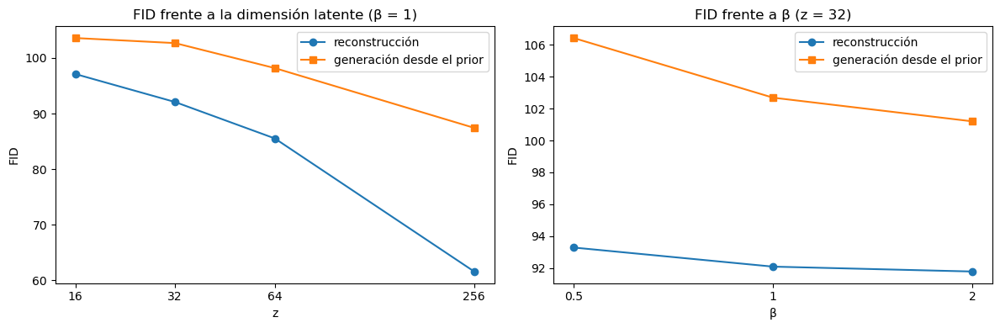

In [19]:
# Tabla resumen de las secciones 5 a 7.
results_df = pd.DataFrame(
    {label(e): {k: v for k, v in RESULTS[e["name"]].items() if not k.startswith("_")} for e in READY}
).T
results_df = results_df[["MSE", "SSIM", "FID reconstrucción", "FID prior", "KL total (nats)", "dim. activas", "norma μ"]]
display(results_df.round(4))

# FID frente a la dimensión latente (β = 1) y frente a β (z = 32).
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
latent_series = sorted((e for e in READY if e["beta"] == 1.0), key=lambda e: e["latent"])
beta_series = sorted((e for e in READY if e["latent"] == 32), key=lambda e: e["beta"])
for ax, series, key, title in (
    (axes[0], latent_series, "latent", "FID frente a la dimensión latente (β = 1)"),
    (axes[1], beta_series, "beta", "FID frente a β (z = 32)"),
):
    xs = [e[key] for e in series]
    ax.plot(xs, [RESULTS[e["name"]]["FID reconstrucción"] for e in series], "o-", label="reconstrucción")
    ax.plot(xs, [RESULTS[e["name"]]["FID prior"] for e in series], "s-", label="generación desde el prior")
    ax.set_xscale("log", base=2)
    ax.set_xticks(xs)
    ax.set_xticklabels([f"{x:g}" for x in xs])
    ax.set_xlabel("z" if key == "latent" else "β")
    ax.set_ylabel("FID")
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()

**Resultados del diagnóstico latente y de la generación** (`val` para la KL y las dimensiones activas; `1000` muestras del prior para el FID):

| Modelo | KL (nats) | Dim. activas | Norma de μ (prior) | FID reconstrucción | FID desde el prior | Diferencia |
| --- | --- | --- | --- | --- | --- | --- |
| `z=16, β=1` | `51.3` | `16 / 16` | `3.65` (`4.00`) | `97.12` | `103.60` | `6.5` |
| `z=32, β=1` | `90.1` | `32 / 32` | `5.30` (`5.66`) | `92.08` | `102.69` | `10.6` |
| `z=32, β=0.5` | `102.1` | `32 / 32` | `5.44` (`5.66`) | `93.28` | `106.43` | `13.2` |
| `z=32, β=2` | `78.1` | `32 / 32` | `5.34` (`5.66`) | `91.77` | `101.20` | `9.4` |
| `z=64, β=1` | `154.6` | `64 / 64` | `7.68` (`8.00`) | `85.53` | `98.19` | `12.7` |
| `z=256, β=1` | `350.6` | `256 / 256` | `14.92` (`16.00`) | `61.57` | `87.43` | `25.9` |

- **Ninguna dimensión apagada.** En todos los modelos están activas el `100 %` de las dimensiones. Es coherente con que el latente de estos tamaños no sea demasiado grande para lo que el modelo quiere guardar: el límite de capacidad lo marca la dimensión y no la `β`, y con `β` entre `0.5` y `2` la regularización no basta para apagar ninguna. No hemos probado `β` mayores (para eso está `INCLUDE_EXTRA_BETA`).
- **Los códigos se parecen al prior.** Las medias μ siguen una gaussiana estándar muy de cerca en todos los modelos (histograma), y su norma media está entre el `91 %` y el `96 %` de la esperada para el prior (`√z`). El efecto de `β` es pequeño: la KL por dimensión baja con `β` creciente, pero todas las curvas son similares.
- **El FID desde el prior también mejora con `z`** (`103.6 → 102.7 → 98.2 → 87.4`), pero menos que el de reconstrucción, de modo que **la diferencia entre generar y reconstruir crece con `z`** (de `6.5` a `25.9`). Es decir, un latente mayor recoge mucho más detalle de las imágenes, pero el prior `N(0, I)` cubre peor el conjunto de códigos de ese espacio. No es el compromiso que esperábamos («`z` pequeño genera mejor»): aquí generar también mejora con `z`, aunque a un ritmo menor que reconstruir.
- **Efecto de `β` en la generación (`z = 32`).** El FID desde el prior baja de forma monótona al subir `β` (`106.4 → 102.7 → 101.2`), la dirección que predice la teoría, pero son `5` puntos en total con una sola semilla, por lo que **no podemos asegurar que sea más que ruido**. Para confirmarlo harían falta valores de `β` más altos o más semillas.
- **Muestras generadas** (figura): en todos los modelos son **caras plausibles y variadas** (pelo, pose, expresión, sexo y fondo distintos). Con `z = 16` y `z = 32` son más suaves y limpias pero borrosas, y algunas salen con rasgos poco definidos (la cuarta de `z = 16`); con `z = 64` aparecen más variedad y algunas deformaciones; con `z = 256` son las más detalladas pero también las que tienen **más artefactos** (ojos, bocas y contornos deformados). Es decir, el mejor FID del `z = 256` no equivale a que las muestras se vean mejor a simple vista.

---

## **8. Morphing sobre los 24 pares: lineal frente a esférica**

Para cada modelo y cada uno de los `24` pares de la sección 3 codificamos los dos extremos con $\mu(x)$ y decodificamos `41` puntos de dos trayectorias (experimento A del README):

$$\text{Lineal: } z_\alpha = (1-\alpha) z_A + \alpha z_B \qquad\qquad \text{SLERP: } z_\alpha = \frac{\sin((1-\alpha)\Omega)}{\sin \Omega} z_A + \frac{\sin(\alpha \Omega)}{\sin \Omega} z_B$$

con $\Omega$ el ángulo entre $z_A$ y $z_B$. Medimos, **por par**, estas cantidades (la tabla final promedia los `12` pares de cada tipo):

| Métrica | Qué mide | Cómo leerla |
| --- | --- | --- |
| **FID de los fotogramas** | Si los fotogramas intermedios parecen caras reales (todos los fotogramas de los `24` pares, sin los extremos, frente a la referencia de `test`) | Menor es mejor. **Solo orienta**: son `24` trayectorias muy correlacionadas, no `936` imágenes independientes, así que sirve para comparar modelos entre sí y no como un valor absoluto |
| **Uniformidad de los pasos (CV)** | Cuánto varía el cambio de píxeles entre fotogramas consecutivos: desviación típica entre media | `0` sería un cambio perfectamente regular; un valor alto indica tramos casi parados y saltos |
| **Salto máximo** | El mayor cambio entre dos fotogramas consecutivos dividido por el cambio medio | `1` sería un cambio regular; un valor alto indica un salto brusco en algún punto |
| **Nitidez del punto medio** | Varianza del laplaciano en $\alpha = 0.5$ dividida por la media de la de los dos extremos reconstruidos | Cerca de `1`, el punto medio es tan nítido como los extremos; menor que `1`, es más borroso |
| **Norma del punto medio** | Norma de $z_{0.5}$ dividida por la media de las normas de los extremos | La teoría predice `≈ 0.71` para la interpolación lineal entre vectores casi ortogonales, y `≈ 1` para SLERP |
| **Error en los extremos** | MSE entre la reconstrucción de cada extremo y la imagen original | Cuánto del error del morphing viene de la reconstrucción y no de la interpolación |

**Qué no medimos.** No hay ninguna métrica de **conservación de la identidad** ni de plausibilidad perceptual por fotograma, y las medidas anteriores son aproximaciones sencillas: la uniformidad de los pasos en píxeles no equivale a que el cambio *se vea* uniforme. Por eso la valoración numérica se complementa con las figuras de la sección 8.2 y los GIF de la sección 9, que son una inspección visual de unos pocos pares.

In [20]:
ALPHAS = np.linspace(0.0, 1.0, N_ALPHAS, dtype=np.float32)
MID = N_ALPHAS // 2
RGB_TO_GRAY = np.array([0.299, 0.587, 0.114], dtype="float32")


def interpolate_paths(z_a, z_b, alphas, method):
    """Trayectorias entre cada z_a[i] y z_b[i]. Devuelve un array (pares, pasos, dimensión)."""
    a = alphas[None, :, None]
    linear = (1.0 - a) * z_a[:, None, :] + a * z_b[:, None, :]
    if method == "linear":
        return linear
    # SLERP; si los dos vectores son casi paralelos, se reduce a la interpolación lineal.
    cos_omega = np.sum(z_a * z_b, axis=1) / (np.linalg.norm(z_a, axis=1) * np.linalg.norm(z_b, axis=1))
    omega = np.arccos(np.clip(cos_omega, -1.0, 1.0))[:, None, None]
    sin_omega = np.sin(omega)
    slerp = (np.sin((1.0 - a) * omega) * z_a[:, None, :] + np.sin(a * omega) * z_b[:, None, :]) / np.maximum(sin_omega, 1e-8)
    return np.where(sin_omega < 1e-6, linear, slerp)


def laplacian_variance(frames):
    # Nitidez: varianza del laplaciano de la luminancia. frames: (..., H, W, 3)
    gray = frames @ RGB_TO_GRAY
    laplacian = (4.0 * gray[..., 1:-1, 1:-1] - gray[..., :-2, 1:-1] - gray[..., 2:, 1:-1]
                 - gray[..., 1:-1, :-2] - gray[..., 1:-1, 2:])
    return laplacian.var(axis=(-2, -1))


MORPH_FRAMES = {}   # (experimento, método) -> fotogramas uint8 (pares, pasos, 64, 64, 3)
morph_rows = []
morph_fid = {}

for experiment in READY:
    name = experiment["name"]
    z_a, z_b = encode_mean(name, x_test[PAIR_A]), encode_mean(name, x_test[PAIR_B])
    for method in ("linear", "slerp"):
        z_path = interpolate_paths(z_a, z_b, ALPHAS, method)
        n_pairs, n_steps, latent = z_path.shape
        frames = decode(name, z_path.reshape(-1, latent)).reshape(n_pairs, n_steps, IMG_SIZE, IMG_SIZE, CHANNELS)

        steps = np.abs(np.diff(frames, axis=1)).mean(axis=(2, 3, 4))
        sharpness = laplacian_variance(frames)
        norms = np.linalg.norm(z_path, axis=2)
        endpoint_mse = 0.5 * (((frames[:, 0] - x_test[PAIR_A]) ** 2).mean(axis=(1, 2, 3))
                              + ((frames[:, -1] - x_test[PAIR_B]) ** 2).mean(axis=(1, 2, 3)))
        for pair in range(n_pairs):
            morph_rows.append({
                "experimento": label(experiment),
                "método": method,
                "tipo": PAIR_TYPES[pair],
                "uniformidad (CV)": steps[pair].std() / steps[pair].mean(),
                "salto máximo": steps[pair].max() / steps[pair].mean(),
                "nitidez punto medio": sharpness[pair, MID] / (0.5 * (sharpness[pair, 0] + sharpness[pair, -1])),
                "norma punto medio": norms[pair, MID] / (0.5 * (norms[pair, 0] + norms[pair, -1])),
                "error extremos (MSE)": endpoint_mse[pair],
            })
        morph_fid[(label(experiment), method)] = calculate_fid(
            frames[:, 1:-1].reshape(-1, IMG_SIZE, IMG_SIZE, CHANNELS), FID_REFERENCE
        )
        MORPH_FRAMES[(name, method)] = (np.clip(frames, 0, 1) * 255).round().astype(np.uint8)
    print(f"{label(experiment):>14}: FID de los fotogramas  lineal {morph_fid[(label(experiment), 'linear')]:.2f} | "
          f"esférica {morph_fid[(label(experiment), 'slerp')]:.2f}")

morph_df = pd.DataFrame(morph_rows)

I0000 00:00:1793954266.525425   11657 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_4276__.1


     z=32, β=1: FID de los fotogramas  lineal 121.99 | esférica 121.26


I0000 00:00:1793954296.216698   11657 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_12835__.1


     z=16, β=1: FID de los fotogramas  lineal 124.77 | esférica 128.50


I0000 00:00:1793954322.419722   11655 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_21394__.1


     z=64, β=1: FID de los fotogramas  lineal 120.83 | esférica 121.67


... (2 outputs left out)

I0000 00:00:1793954374.478714   11656 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_38512__.1


     z=32, β=2: FID de los fotogramas  lineal 121.34 | esférica 122.97


I0000 00:00:1793954400.888990   11656 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_47071__.1


    z=256, β=1: FID de los fotogramas  lineal 99.19 | esférica 99.62


In [21]:
# Tabla 1: medias sobre los 24 pares, por modelo y método.
overall = morph_df.groupby(["experimento", "método"], sort=False).mean(numeric_only=True)
overall.insert(0, "FID fotogramas", [morph_fid[(experiment, method)] for experiment, method in overall.index])
display(overall.round(3))

FID fotogramas  uniformidad (CV)  salto máximo  \
experimento método                                                   
z=32, β=1   linear         121.986             0.121         1.189   
            slerp          121.262             0.202         1.323   
z=16, β=1   linear         124.774             0.130         1.212   
            slerp          128.504             0.212         1.368   
z=64, β=1   linear         120.833             0.123         1.172   
            slerp          121.669             0.201         1.303   
z=32, β=0.5 linear         122.940             0.129         1.201   
            slerp          125.254             0.211         1.341   
z=32, β=2   linear         121.342             0.121         1.186   
            slerp          122.970             0.208         1.326   
z=256, β=1  linear          99.186             0.170         1.227   
            slerp           99.625             0.204         1.300   

                    nitidez punto medio  norma punto medio  \
experimento método                                           
z=32, β=1   linear                0.596              0.714   
            slerp                 0.891              1.009   
z=16, β=1   linear                0.601              0.723   
            slerp                 0.899              1.018   
z=64, β=1   linear                0.566              0.718   
            slerp                 0.854              1.004   
z=32, β=0.5 linear                0.601              0.716   
            slerp                 0.903              1.012   
z=32, β=2   linear                0.618              0.713   
            slerp                 0.912              1.010   
z=256, β=1  linear                0.630              0.719   
            slerp                 0.816              1.002   

                    error extremos (MSE)  
experimento método                        
z=32, β=1   linear                 0.012  
            slerp                  0.012  
z=16, β=1   linear                 0.017  
            slerp                  0.017  
z=64, β=1   linear                 0.009  
            slerp                  0.009  
z=32, β=0.5 linear                 0.012  
            slerp                  0.012  
z=32, β=2   linear                 0.012  
            slerp                  0.012  
z=256, β=1  linear                 0.005  
            slerp                  0.005

In [22]:
# Tabla 2: uniformidad y salto máximo separados por tipo de par (fáciles frente a difíciles).
by_type = morph_df.groupby(["experimento", "método", "tipo"], sort=False)[["uniformidad (CV)", "salto máximo", "nitidez punto medio"]].mean()
display(by_type.unstack("tipo").round(3))

uniformidad (CV)         salto máximo          \
tipo                          fácil difícil        fácil difícil   
experimento método                                                 
z=32, β=1   linear            0.126   0.117        1.198   1.179   
            slerp             0.182   0.223        1.306   1.340   
z=16, β=1   linear            0.151   0.108        1.239   1.185   
            slerp             0.201   0.223        1.342   1.394   
z=64, β=1   linear            0.109   0.138        1.154   1.189   
            slerp             0.171   0.232        1.286   1.320   
z=32, β=0.5 linear            0.131   0.128        1.205   1.198   
            slerp             0.186   0.236        1.310   1.373   
z=32, β=2   linear            0.126   0.116        1.200   1.172   
            slerp             0.180   0.236        1.304   1.348   
z=256, β=1  linear            0.156   0.184        1.211   1.243   
            slerp             0.183   0.225        1.312   1.288   

                   nitidez punto medio          
tipo                             fácil difícil  
experimento método                              
z=32, β=1   linear               0.716   0.477  
            slerp                1.007   0.774  
z=16, β=1   linear               0.772   0.431  
            slerp                1.077   0.720  
z=64, β=1   linear               0.714   0.418  
            slerp                1.043   0.665  
z=32, β=0.5 linear               0.726   0.475  
            slerp                1.034   0.771  
z=32, β=2   linear               0.746   0.491  
            slerp                1.042   0.781  
z=256, β=1  linear               0.729   0.531  
            slerp                0.971   0.660

### **8.2 Secuencias visuales**

Comparamos visualmente los modelos con **dos pares concretos**, el primer par fácil y el primer par difícil del conjunto. Cada figura muestra una fila por modelo con `9` pasos de la misma interpolación; hay una figura por método (lineal y SLERP). Es una inspección cualitativa de **solo dos pares**: sirve para ilustrar lo que miden los números, no para sustituirlos.

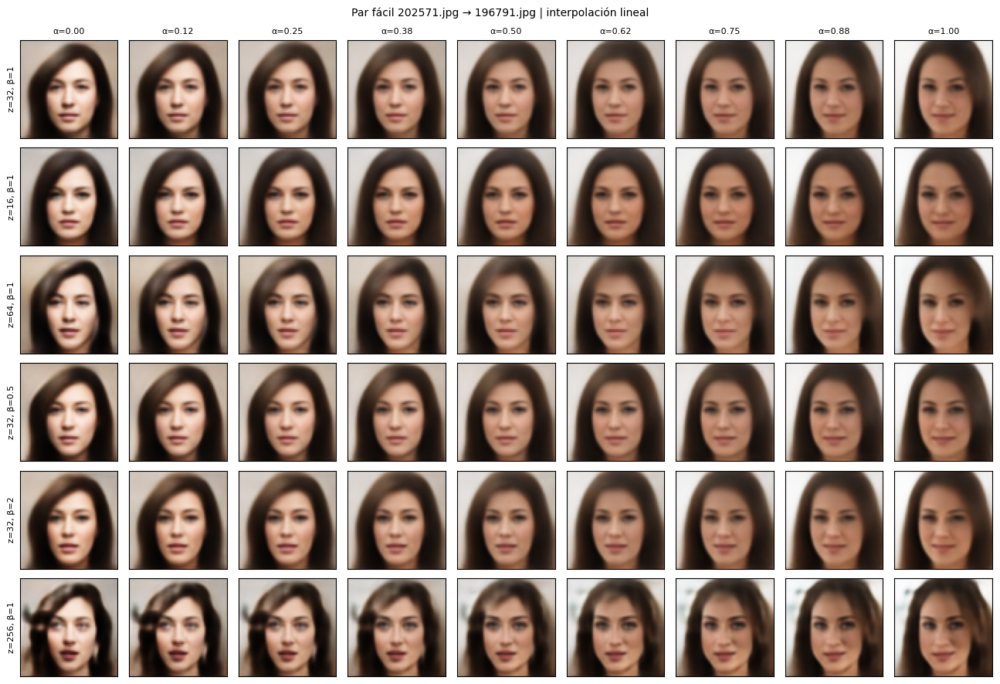

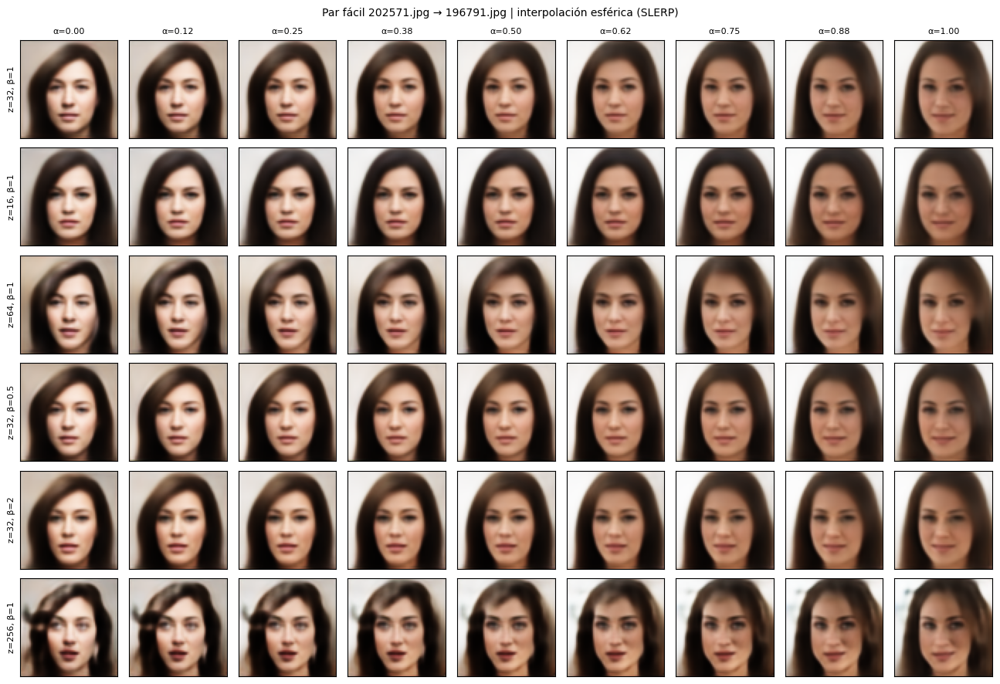

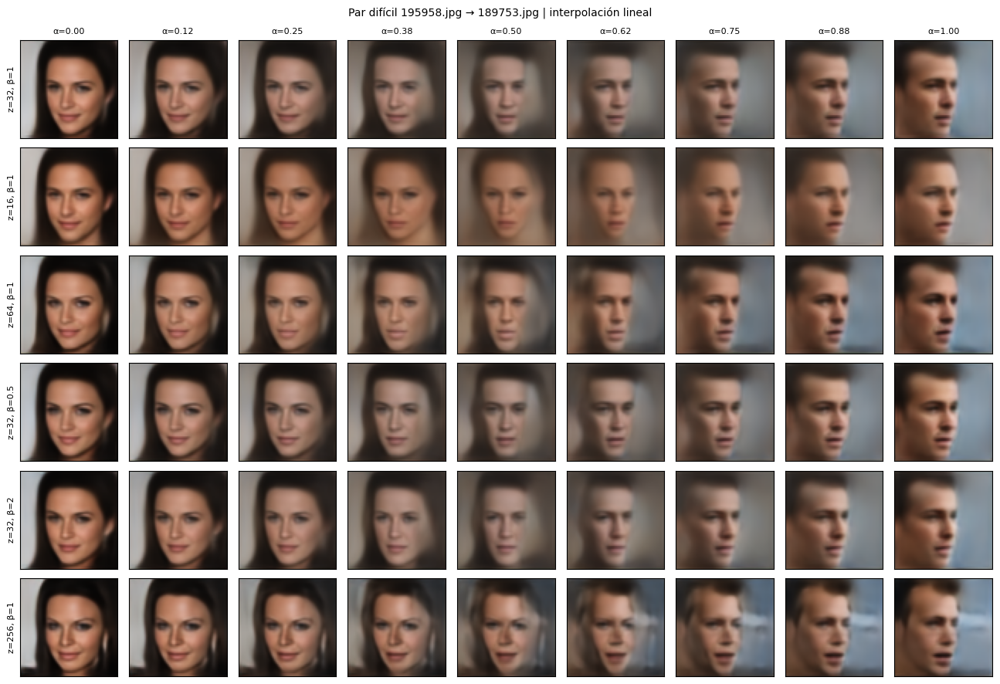

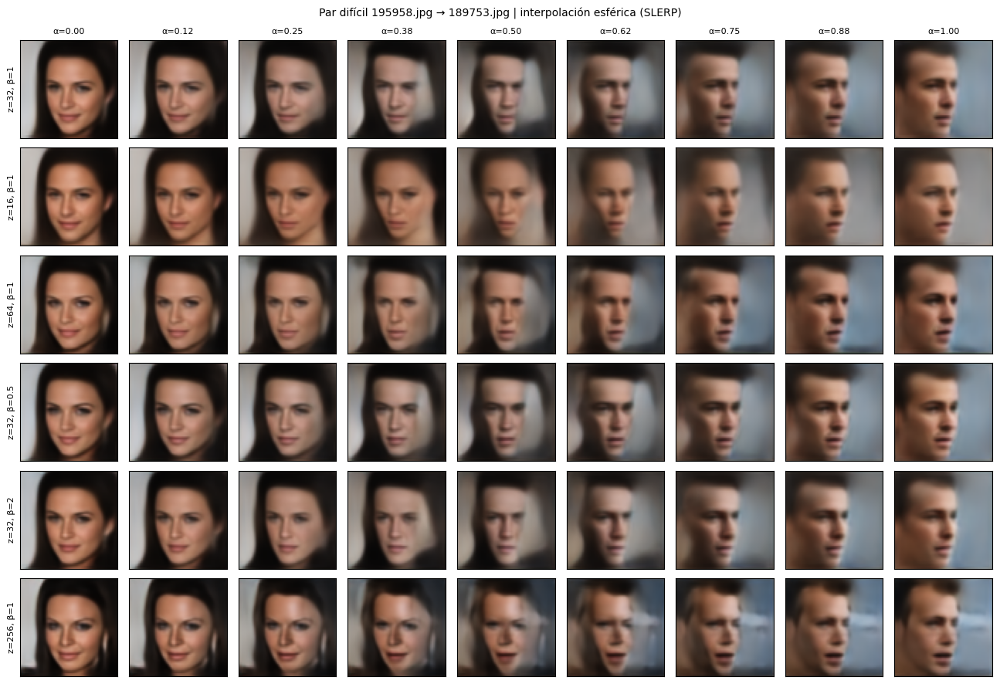

In [23]:
def show_morph_grid(pair_index, method, steps=9):
    columns = np.linspace(0, N_ALPHAS - 1, steps).astype(int)
    pair = EVAL_PAIRS[pair_index]
    fig, axes = plt.subplots(len(READY), steps, figsize=(1.45 * steps, 1.5 * len(READY)), squeeze=False)
    for row, experiment in enumerate(READY):
        frames = MORPH_FRAMES[(experiment["name"], method)][pair_index]
        for column, step in enumerate(columns):
            axes[row, column].imshow(frames[step])
            axes[row, column].set_xticks([])
            axes[row, column].set_yticks([])
            if row == 0:
                axes[row, column].set_title(f"α={ALPHAS[step]:.2f}", fontsize=8)
        axes[row, 0].set_ylabel(label(experiment), fontsize=8)
    kind = "interpolación lineal" if method == "linear" else "interpolación esférica (SLERP)"
    plt.suptitle(f"Par {pair['type']} {pair['a']} → {pair['b']} | {kind}", fontsize=10)
    plt.tight_layout()
    plt.show()


EASY_EXAMPLE = int(np.flatnonzero(PAIR_TYPES == "fácil")[0])
HARD_EXAMPLE = int(np.flatnonzero(PAIR_TYPES == "difícil")[0])
for pair_index in (EASY_EXAMPLE, HARD_EXAMPLE):
    for method in ("linear", "slerp"):
        show_morph_grid(pair_index, method)

**Resultados numéricos** (media de los `24` pares; para `z = 256` el `FID de los fotogramas` es `99.19` / `99.62`):

| Modelo | FID fotogramas (lineal / SLERP) | Nitidez punto medio (lineal / SLERP) | Uniformidad CV (lineal / SLERP) | Salto máximo (lineal / SLERP) |
| --- | --- | --- | --- | --- |
| `z=16, β=1` | `124.8 / 128.5` | `0.60 / 0.90` | `0.130 / 0.212` | `1.21 / 1.37` |
| `z=32, β=1` | `122.0 / 121.3` | `0.60 / 0.89` | `0.121 / 0.202` | `1.19 / 1.32` |
| `z=32, β=0.5` | `122.9 / 125.3` | `0.60 / 0.90` | `0.129 / 0.211` | `1.20 / 1.34` |
| `z=32, β=2` | `121.3 / 123.0` | `0.62 / 0.91` | `0.121 / 0.208` | `1.19 / 1.33` |
| `z=64, β=1` | `120.8 / 121.7` | `0.57 / 0.85` | `0.123 / 0.201` | `1.17 / 1.30` |
| `z=256, β=1` | `99.2 / 99.6` | `0.63 / 0.82` | `0.170 / 0.204` | `1.23 / 1.30` |

**(a) Lineal frente a esférica.**
- **La teoría se cumple en la norma.** En $lpha = 0.5$ la norma baja a `0.71`-`0.72` de la de los extremos con la interpolación lineal (el `0.71` que predice la teoría para vectores casi ortogonales) y se mantiene en `1.00`-`1.02` con SLERP, en todos los modelos y en todas las dimensiones.
- **SLERP conserva mucho mejor la nitidez del punto medio:** `0.82`-`0.91` frente a `0.57`-`0.63` de la lineal. En la figura se ve: con la interpolación lineal el punto medio es el más borroso y desvaído, y con SLERP los rasgos están más definidos. Conviene leer esta métrica con cuidado: la varianza del laplaciano también sube con el ruido y los artefactos, de modo que un valor alto no demuestra por sí solo una imagen mejor.
- **En el FID de los fotogramas no hay diferencia clara:** las diferencias entre las dos trayectorias son de `0.4` a `3.7` puntos, sin signo constante (SLERP es algo peor en `z = 16` y `β = 0.5`, y algo mejor en `z = 32`, `β = 1`), dentro del ruido.
- **SLERP es menos uniforme en píxeles:** el coeficiente de variación de los pasos es `≈ 0.20` frente a `≈ 0.12` (`z ≤ 64`), y el salto máximo `1.30`-`1.37` veces el cambio medio frente a `1.17`-`1.21`. Es decir, con SLERP el cambio entre fotogramas es algo más irregular. No hemos investigado por qué.
- Resumen: **SLERP da puntos medios más nítidos pero un cambio algo menos regular, sin mejora medible en el FID**; no es una ventaja clara.

**(b) Fáciles frente a difíciles.** La nitidez del punto medio **cae mucho con los pares difíciles**: con la interpolación lineal pasa de `0.71`-`0.77` (fáciles) a `0.42`-`0.53` (difíciles), y con SLERP de `0.97`-`1.08` a `0.66`-`0.78`. Con pose y sexo distintos, el punto medio es mucho más borroso. La uniformidad y el salto máximo cambian poco con el tipo de par en la interpolación lineal; con SLERP, los pares difíciles son algo más irregulares (`CV ≈ 0.22`-`0.24` frente a `0.17`-`0.20`).

**(c) Qué modelo hace mejor morphing.**
- **Por los números**, `z = 256` es el mejor: su FID de los fotogramas es `≈ 99`, unos `22`-`29` puntos por debajo del resto, que quedan entre `121` y `128` y no se distinguen entre sí (`z = 32` y `z = 64` prácticamente empatan, `z = 16` es algo peor). Coincide con el orden del FID de reconstrucción y de generación. Se mantiene la salvedad de que `z = 256` se entrenó con lote real. El **error en los extremos** también ordena los modelos como la reconstrucción (`MSE` `0.017`, `0.012`, `0.009` y `0.005` para `z = 16`, `32`, `64` y `256`).
- **Por la inspección visual** (los `2` pares de las figuras), `z = 256` es el de mayor detalle en los extremos y en el punto medio, pero también el que tiene más artefactos: en el par fácil aparece un *ghosting* claro en el pelo a la izquierda (`α = 0.12`-`0.5`) y en el par difícil las caras intermedias tienen gestos deformados (bocas abiertas, ojos desiguales) en `α = 0.5`-`0.62`. Los modelos de `z = 16` a `64` producen transiciones más suaves y limpias pero más borrosas; `z = 16` es el más desvaído en el punto medio.
- **`β` no se nota** en las figuras: las filas de `β = 0.5`, `1` y `2` son casi indistinguibles.

**(d) *Ghosting*, caras dobles y saltos.** En el par **fácil** la transición es continua en todos los modelos y no hay caras dobles. En el par **difícil**, con el cambio de sexo y de giro de la cabeza, los fotogramas intermedios son una mezcla borrosa en la que se ven restos de ambas caras (una zona más clara a la izquierda procedente de la primera, en `z = 32`, `64` y `β = 0.5`/`2`, de `α = 0.38` a `0.62`), sin llegar a una cara doble nítida; la cara va girando de forma gradual, no a saltos. Es una observación de **dos pares** y no se puede generalizar.

**Limitaciones de esta evaluación.** El FID de los fotogramas se calcula sobre `24` trayectorias muy correlacionadas, por lo que sirve para comparar modelos entre sí pero no como valor absoluto (de hecho es mucho mayor que el de reconstrucción, por ejemplo `122` frente a `92` en `z = 32`). No hay medida de identidad.

---

## **9. GIF del morphing**

Guardamos, para cada modelo, un GIF de `60` fotogramas de **un par difícil** (el mismo de la sección 8.2) con la interpolación lineal a la izquierda y la esférica a la derecha, para poder verlos lado a lado. Se guardan en `gif/` con el nombre `fusion_vae2_<experimento>_morphing.gif`. Para que el notebook no crezca, solo se muestra en pantalla uno de ellos (el modelo base, `z = 32`, `β = 1`, si está disponible); los demás están en la carpeta.

GIF guardado en '/home/sanru/Escritorio/7_cuatri/PCD/project/morphing/gif/fusion_vae2_vae_complex2_z32_b1_morphing.gif' | 60 fotogramas (izquierda: lineal, derecha: SLERP)


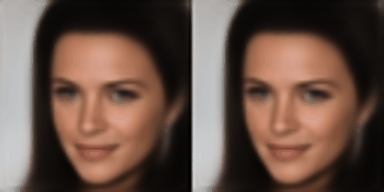

GIF guardado en '/home/sanru/Escritorio/7_cuatri/PCD/project/morphing/gif/fusion_vae2_vae_complex2_z16_b1_morphing.gif' | 60 fotogramas (izquierda: lineal, derecha: SLERP)
GIF guardado en '/home/sanru/Escritorio/7_cuatri/PCD/project/morphing/gif/fusion_vae2_vae_complex2_z64_b1_morphing.gif' | 60 fotogramas (izquierda: lineal, derecha: SLERP)
GIF guardado en '/home/sanru/Escritorio/7_cuatri/PCD/project/morphing/gif/fusion_vae2_vae_complex2_z32_b0p5_morphing.gif' | 60 fotogramas (izquierda: lineal, derecha: SLERP)
GIF guardado en '/home/sanru/Escritorio/7_cuatri/PCD/project/morphing/gif/fusion_vae2_vae_complex2_z32_b2_morphing.gif' | 60 fotogramas (izquierda: lineal, derecha: SLERP)
GIF guardado en '/home/sanru/Escritorio/7_cuatri/PCD/project/morphing/gif/fusion_vae2_vae_complex1_latent256_morphing.gif' | 60 fotogramas (izquierda: lineal, derecha: SLERP)


In [24]:
GIF_DIR = PROCESSED_DIR.parent.parent / "gif"
N_GIF_FRAMES = 60
FRAME_MS = 50
GIF_SIZE = 192
DISPLAY_GIF_FOR = "vae_complex2_z32_b1"

gif_alphas = np.linspace(0.0, 1.0, N_GIF_FRAMES, dtype=np.float32)
GIF_DIR.mkdir(parents=True, exist_ok=True)

for experiment in READY:
    name = experiment["name"]
    z_a = encode_mean(name, x_test[PAIR_A[HARD_EXAMPLE]][None, ...])
    z_b = encode_mean(name, x_test[PAIR_B[HARD_EXAMPLE]][None, ...])
    sides = []
    for method in ("linear", "slerp"):
        z_path = interpolate_paths(z_a, z_b, gif_alphas, method)[0]
        sides.append(decode(name, z_path))
    frames = []
    for linear_frame, slerp_frame in zip(*sides):
        side_by_side = np.concatenate([linear_frame, slerp_frame], axis=1)
        frames.append(
            Image.fromarray((np.clip(side_by_side, 0, 1) * 255).astype(np.uint8))
            .resize((2 * GIF_SIZE, GIF_SIZE), Image.Resampling.BICUBIC)
        )
    gif_path = (GIF_DIR / f"fusion_vae2_{name}_morphing.gif").resolve()
    frames[0].save(gif_path, save_all=True, append_images=frames[1:], duration=FRAME_MS, loop=0)
    print(f"GIF guardado en '{gif_path}' | {len(frames)} fotogramas (izquierda: lineal, derecha: SLERP)")
    if name == DISPLAY_GIF_FOR:
        display(IPyImage(filename=str(gif_path)))

---

## **10. Decisiones de diseño, resultados y siguiente paso**

### **10.1 Decisiones de diseño**

- **Un factor cada vez, con un modelo base.** Seguimos el README: `β ∈ {0.5, 1, 2}` con `z = 32` y `z ∈ {16, 32, 64}` con `β = 1`. El modelo base (`z = 32`, `β = 1`) es común a los dos barridos, así que son `5` entrenamientos y no `9`. No hacemos la rejilla completa (`z × β`) por coste; por tanto **no podemos estudiar interacciones** entre ambos factores.
- **Referencia de `z = 256`.** Reutilizamos el modelo de `VAE_complex1` en lugar de reentrenarlo, de modo que los resultados de los dos notebooks se pueden comparar (misma arquitectura, pérdida, semilla y datos), con la salvedad de que `VAE_complex1` se entrenó con lote real de `128` y los modelos nuevos con acumulación de gradientes.
- **Misma receta de entrenamiento para todos los modelos nuevos.** Mismas épocas, lote efectivo, programa de la tasa de aprendizaje, semilla y pérdida de reconstrucción. Así la única diferencia entre ellos es la que estamos estudiando. **Acumulación de gradientes:** para que el lote efectivo de `128` quepa en la GPU, lo procesamos en `2` micro-lotes de `64`. El modelo de referencia de `VAE_complex1` se entrenó con lote real, por lo que esa comparación tiene una pequeña diferencia de procedimiento.
- **`β` normalizada.** La KL se divide por `12288`, como en `VAE_complex1`. Esta escala **hace que `β` no sea comparable con la de otros trabajos** y que el rango `0.5`-`2` pueda ser estrecho; la opción `INCLUDE_EXTRA_BETA` añade `β = 8` para comprobarlo.
- **Pares fijos y guardados.** Los `24` pares se construyen con una regla y se guardan en `data/processed/eval_pairs.json` como identificadores de imagen, para que los usen también el morphing clásico y la DCGAN. Quedan fuera de los pares las `2000` primeras imágenes de `test`, que usa el FID.
- **Métricas de morphing sencillas.** Las medimos por par y las promediamos por tipo. Son aproximaciones y no sustituyen a una medida de identidad ni de calidad perceptual.
- **Una sola semilla.** No repetimos entrenamientos, por coste. Las diferencias pequeñas no deben interpretarse.

### **10.2 Resultados**

| Modelo | `z` | `β` | FID reconstrucción | FID desde el prior | Dim. activas | FID fotogramas (lineal / SLERP) |
| --- | --- | --- | --- | --- | --- | --- |
| `AE_complex2_VGG` (determinista) | 256 | — | 61.17 | — | — | — |
| `VAE_complex1` (recalculado aquí) | 256 | 1 | 61.57 | 87.43 | 256 / 256 | 99.19 / 99.62 |
| `VAE_complex2` | 16 | 1 | 97.12 | 103.60 | 16 / 16 | 124.77 / 128.50 |
| `VAE_complex2` (base) | 32 | 1 | 92.08 | 102.69 | 32 / 32 | 121.99 / 121.26 |
| `VAE_complex2` | 64 | 1 | 85.53 | 98.19 | 64 / 64 | 120.83 / 121.67 |
| `VAE_complex2` | 32 | 0.5 | 93.28 | 106.43 | 32 / 32 | 122.94 / 125.25 |
| `VAE_complex2` | 32 | 2 | 91.77 | 101.20 | 32 / 32 | 121.34 / 122.97 |

El FID de reconstrucción y el de generación del modelo `z = 256` coinciden con los de `VAE_complex1` (`61.57` y `87.43`), como debía ocurrir al cargar los mismos *checkpoints* con el mismo protocolo. El FID de los fotogramas de ese modelo (`99.19` / `99.62`) es nuevo y se calcula aquí con los `24` pares de la sección 3. Los FID de los fotogramas no son comparables con los de reconstrucción ni generación, y los `24` pares no son independientes. Recordemos también que `z = 256` se entrenó con lote real de `128` y las demás filas con acumulación de gradientes.

### **10.3 Coste computacional**

Los `5` modelos nuevos tardaron lo mismo por época (`99`-`101 s`, es decir, `≈ 50 min` por modelo y `≈ 4 h 10 min` en total) en la RTX 3050 de portátil, con lotes de `128` procesados como `2` micro-lotes de `64`. **`z` no cambia el coste en tiempo**, como esperábamos, porque solo afecta a las capas densas de los extremos. En parámetros sí hay diferencia: `z = 16` tiene `1.88 M` (`0.82 M` el encoder y `1.06 M` el decoder) y `z = 256`, `4.83 M` (`2.79 M` y `2.04 M`), unas `2.6` veces más. No tenemos el tiempo por época de `VAE_complex1` para compararlo, pero la arquitectura es la misma. Dado que `z` es gratis en tiempo y `β` en el rango probado casi no cambia nada, **el coste no es un argumento para preferir un `z` pequeño**.

### **10.4 Reflexión y siguiente paso**

**Respuesta a cada experimento del README** (con una sola semilla por configuración y las limitaciones ya descritas):

- **B. Dimensión latente: es el factor que más importa.** Con `β = 1`, reconstrucción (MSE, SSIM, FID), generación desde el prior y morphing (FID de los fotogramas, nitidez, error en los extremos) mejoran todos con `z`, y los modelos quedan ordenados igual por las tres. Entre `z = 16` y `z = 64` la mejora es clara y supera el ruido de la métrica (`11.6` puntos de FID de reconstrucción). Ninguno tiene dimensiones apagadas, y el modelo de `256` es el mejor en todo, aunque su diferencia con los demás mezcla `z` con el cambio de procedimiento (lote real frente a acumulación). **No hemos probado `z` mayor de `256`**, así que no sabemos si la mejora se satura. La ganancia en generación es menor que en reconstrucción, y la diferencia entre ambas crece con `z` (`6.5` a `25.9`): un latente mayor se reconstruye mucho mejor pero encaja peor en el prior.
- **C. Regularización: con `β` entre `0.5` y `2`, el efecto es casi nulo.** La KL baja `12` nats por cada duplicación de `β`, pero la reconstrucción (`MSE`, `SSIM`, `FID`) y el morphing no cambian de forma apreciable, y el FID desde el prior mejora `5` puntos de forma monótona con `β` pero sin poder asegurar que sea más que ruido. La razón probable es que, con nuestra normalización (KL dividida por `12288`), el término KL pesa solo un `2`-`5 %` de la pérdida para esos valores y el rango es demasiado estrecho para ver un cambio de régimen. Para saber si la `β` tiene algún efecto real habría que probar valores mucho mayores (`INCLUDE_EXTRA_BETA`, `β = 8`, o más).
- **A. Lineal frente a esférica: SLERP no es una mejora clara.** Se cumple la teoría de la norma (`0.71` frente a `1.00`) y SLERP da puntos medios claramente más nítidos, pero el cambio entre fotogramas es menos regular y el FID de los fotogramas no mejora de forma medible. En los pares difíciles el punto medio es mucho más borroso con cualquiera de los dos métodos. Sigue sin resolver el problema de fondo: en pares con pose y sexo muy distintos, el morphing en el espacio latente produce mezclas borrosas con restos de ambas caras.

**Configuración recomendada como base.** Para los siguientes experimentos (direcciones semánticas, pérdida perceptual y la comparación con el morphing clásico y la DCGAN) **recomendamos `z = 256`, `β = 1` (el modelo de `VAE_complex1`)**: es el mejor en todas las métricas que hemos medido. Aun así, hay una decisión del grupo pendiente: el README propone `z = 32` como base, y si se quiere seguir esa especificación, los modelos `z = 32` de este notebook (`β = 1` como base) están listos; el precio es una reconstrucción y un morphing claramente peores (`FID` de reconstrucción `92` frente a `62`). Como `β` casi no cambia nada en el rango probado, la elección de `β = 1` es indiferente. Tampoco tenemos evidencia de que `z = 256` sea el óptimo, solo de que es mejor que lo probado.

**Limitaciones que han condicionado las conclusiones.**
- **Una sola semilla por configuración**: no sabemos cuánto varía el FID entre entrenamientos y las diferencias pequeñas (`β`, lineal frente a SLERP, `z = 32` frente a `z = 64` en el morphing) no se pueden interpretar.
- **`z = 256` con otro procedimiento de entrenamiento** (lote real frente a acumulación de gradientes), lo que confunde su comparación con el resto.
- **Rango de `β` estrecho** por la normalización elegida, y rejilla incompleta (sin interacciones `z × β`).
- **Métricas de morphing sencillas y sin medida de identidad**; las figuras solo muestran `2` de los `24` pares.
- **FID de los fotogramas** sobre trayectorias muy correlacionadas, y FID con `1000` imágenes.

**Siguientes pasos ya identificados, con independencia del resultado:**

- **Comparar con el morphing clásico** usando exactamente los mismos `24` pares (`data/processed/eval_pairs.json`), que es el experimento D del README.
- **Curva de identidad** (similitud de cada fotograma con el rostro de origen y de destino con un modelo de reconocimiento facial), que es la métrica que más falta hace para valorar el morphing y que no hemos incorporado todavía.
- **Reentrenar `z = 256`, `β = 1` con la misma acumulación de gradientes** (`≈ 50 min`) para eliminar la diferencia de procedimiento y poder atribuir a `z` la diferencia con los demás modelos.
- **Probar `β` mucho mayores** (`INCLUDE_EXTRA_BETA`, `β = 8`, y más) y, si procede, `z` mayores de `256`, para ver dónde empieza a apagarse el latente y si la mejora con `z` se satura.
- **Variabilidad entre semillas:** repetir el modelo elegido con `2` o `3` semillas más para saber qué diferencias de FID están por encima del ruido.
- **Direcciones semánticas** (experimento E) y **pérdida perceptual** (experimento F) sobre la configuración elegida.